# MorphoNup — architecture analysis

How much does each component contribute? Every arm is MorphoNup with **one** component removed or reduced, retrained with the same splits, seeds, preprocessing rules and training recipe, and compared with MorphoNup on the same outer test rows (Δ = MorphoNup − arm; positive = the component helps). `no_refit` needs no training: it is the base stage that every MorphoNup run already keeps.

Effects are conditional on the rest of the model (removing two components is not the sum of removing each).

**Representative dataset:** DatasetNup_1/Homo_sapiens, outer 5-fold, the three reported seeds of MorphoNup. **Statistics:** per seed, the pooled out-of-fold metrics of MorphoNup and the arm on the same test sequences; Δ with a 95 % t interval over seeds; paired t-test over seeds, Holm-adjusted over the arms of the analysis (3 seeds give little power, so the intervals and the per-seed McNemar tests matter more than the p-values); exact McNemar test per seed.

**Figures** (600-dpi PNG + PDF + CSV, drawn automatically, captions in `figures/figure_catalog.csv`): `deltas` = forest plot of the paired differences (main figure); `boxplot_accuracy` = classic ablation box plot (full model, then each w/o variant; every outer fold as a dot); `delta_heatmap` = Δ of nine metrics; `metrics_panel` = six metrics per variant; `accuracy` = pooled accuracy per variant; `discordance` = the sequences only one model gets right (McNemar); `fold_deltas` = per-fold differences; `roc_pr_parts` = ROC and PR curves per model part; `training_curves` = tune log loss per epoch; `training_diagnostics` = selected epoch and train − test gap; `parameters` = model size. **Tables** (.md, .csv, .tex): `manuscript_table` (main), `metrics_table` (every metric), `comparison` (every statistic).

`RUN_MODE = "background"` trains the missing arms one after another in a single detached job (MorphoNup itself must already be trained for this dataset and k, with the same seeds). Figures and tables are refreshed automatically whenever an arm finishes a seed; the Results cells display them.

In [1]:
DATASET = "DatasetNup_1/Homo_sapiens"
K_FOLDS = 5
SEEDS = [151000, 152000, 153000]          # the reported seeds (config.SEEDS)
GROUP = "architecture"
ARMS = None                               # None = every arm of the group; or a list such as ["no_kmer"]
RUN_MODE = "results_only"                # "background" | "inline" | "results_only"
CHAINS = 2                                # parallel jobs; each trains its share of the arms one after another
ALLOW_BUSY_GPU = False

In [2]:
import os
import sys
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
_null, _err = os.open(os.devnull, os.O_WRONLY), os.dup(2)
os.dup2(_null, 2)                                    # TensorFlow's CUDA start-up lines go to C-level stderr
try:
    import tensorflow  # noqa: F401
finally:
    os.dup2(_err, 2)
    os.close(_null)
    os.close(_err)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "morphonup" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display

from morphonup import config, figures, jobs
from morphonup.cv import run_dir

pd.set_option("display.width", 200, "display.max_columns", 40)


def show(path, width=900):
    """Display a saved figure with its caption (from the folder's figure_catalog.csv)."""
    path = Path(path)
    if not path.exists():
        print("missing:", path.relative_to(ROOT))
        return
    cat = path.parent / "figure_catalog.csv"
    caption = pd.read_csv(cat).set_index("png").suggested_caption.get(path.name, "") if cat.exists() else ""
    display(Markdown(f"**{path.stem}** — `{path.relative_to(ROOT)}`  \n{caption}"))
    display(Image(filename=str(path), width=width))
from morphonup import analysis, arms

ARM_LIST = ARMS or arms.GROUPS[GROUP]
TRAIN = [a for a in ARM_LIST if a in arms.ARMS]
K_DIR = run_dir(DATASET, K_FOLDS).parent
display(arms.table().set_index("arm").loc[ARM_LIST, ["label", "change", "needs_training"]])
full = jobs.progress(DATASET, K_FOLDS, SEEDS)
print("MorphoNup seeds finished:", int((full.status == "done").sum()), "of", len(SEEDS))
gpu, procs = jobs.gpu_status()
print("GPU:", gpu, "| processes:", procs or "none")
print("MorphoNup jobs running:", jobs.running_jobs() or "none")

,label,change,needs_training
arm,,,
no_shape_attenuation,w/o shape attenuation,motifs are plain sequence PWMs (no shape-proto...,True
three_scales,w/o 21-bp motif scale,motif scales 7/11/15 bp (no 21-bp scale),True
global_pool,w/o dyad bins,every DyadPool keeps mean + max only (no 7 dya...,True
no_kmer,w/o k-mer branch,no 1-4-mer composition branch,True
no_physical_adapter,w/o physical adapter,no physical adapter correction; shape still en...,True
no_motif_statistics,w/o motif statistics,no dimer/trimer statistics correction,True
head_dropout_035,Head dropout 0.35,head dropout 0.35 instead of 0.5,True
no_rc_view,w/o RC view,trained and evaluated on the forward strand on...,True
no_sam,w/o SAM,plain AdamW steps (no sharpness-aware minimiza...,True


MorphoNup seeds finished: 3 of 3
GPU: NVIDIA GeForce RTX 4070 Ti, 0 %, 1 MiB, 12282 MiB | processes: none
MorphoNup jobs running: none


## Train the arms

In [3]:
if RUN_MODE == "background":
    LOGS = jobs.launch_arms(DATASET, K_FOLDS, SEEDS, TRAIN, allow_busy_gpu=ALLOW_BUSY_GPU, chains=CHAINS)
    print("launched", len(TRAIN), "arm(s) in", len(LOGS), "job(s); logs:")
    for log in LOGS:
        print(" ", log.relative_to(ROOT))
elif RUN_MODE == "inline":
    gpu, procs = jobs.gpu_status()
    if procs and not ALLOW_BUSY_GPU:
        raise RuntimeError("GPU in use: " + "; ".join(procs))
    import tensorflow as tf
    from morphonup.cv import run
    from morphonup.data import Dataset
    ds = Dataset(config.dataset_folder(DATASET))
    for device in tf.config.list_physical_devices("GPU"):
        tf.config.set_logical_device_configuration(
            device, [tf.config.LogicalDeviceConfiguration(memory_limit=config.gpu_memory_mb(len(ds.y)))])
    for arm in TRAIN:
        run(ds, DATASET, K_FOLDS, SEEDS, arm=arm)
else:
    print("results_only: no training started")

results_only: no training started


## Progress

In [4]:
status = pd.concat([jobs.progress(DATASET, K_FOLDS, SEEDS, arm) for arm in TRAIN], ignore_index=True)
display(status.pivot(index="arm", columns="seed", values="status").loc[TRAIN])
for log in jobs.arm_logs(DATASET, K_FOLDS, SEEDS, TRAIN):
    print("==", log.name)
    print(jobs.tail(log, 6))

seed,151000,152000,153000
arm,,,
no_shape_attenuation,done,done,done
three_scales,done,done,done
global_pool,done,done,done
no_kmer,done,done,done
no_physical_adapter,done,done,done
no_motif_statistics,done,done,done
head_dropout_035,done,done,done
no_rc_view,done,done,done
no_sam,done,done,done


## Results

In [5]:
analysis.refresh(K_DIR)
OUT = K_DIR / "analysis" / GROUP
table = OUT / "manuscript_table.md"
display(Markdown(table.read_text()) if table.exists() else Markdown("_No arm of this group has a finished seed yet._"))

| Part | Model | Seeds | Parameters | Accuracy (%) | MCC | ROC AUC | Δ accuracy (pp) [95 % CI] | Δ correct | Δ MCC [95 % CI] | p (Holm) |
|---|---|---|---|---|---|---|---|---|---|---|
| Reference | MorphoNup (all components) | 3 | 134,442 | 89.10 ± 0.03 | 0.7829 ± 0.0006 | 0.9467 ± 0.0005 | — | — | — | — |
| Motif module | w/o shape attenuation | 3 | 129,886 | 88.95 ± 0.05 | 0.7799 ± 0.0011 | 0.9462 ± 0.0002 | +0.15 [−0.01, +0.32] | +7.0 | +0.0030 [−0.0011, +0.0071] | 0.337 |
| Motif module | w/o 21-bp motif scale | 3 | 117,085 | 88.98 ± 0.12 | 0.7807 ± 0.0024 | 0.9459 ± 0.0009 | +0.12 [−0.15, +0.40] | +5.7 | +0.0022 [−0.0036, +0.0080] | 0.351 |
| Motif module | w/o dyad bins | 3 | 52,682 | 88.04 ± 0.18 | 0.7619 ± 0.0037 | 0.9405 ± 0.0003 | +1.06 [+0.68, +1.45] | +48.7 | +0.0210 [+0.0133, +0.0286] | 0.070 |
| Branches and corrections | w/o k-mer branch | 3 | 121,354 | 88.92 ± 0.11 | 0.7797 ± 0.0023 | 0.9481 ± 0.0004 | +0.18 [−0.04, +0.40] | +8.3 | +0.0031 [−0.0011, +0.0074] | 0.351 |
| Branches and corrections | w/o physical adapter | 3 | 130,396 | 88.43 ± 0.14 | 0.7693 ± 0.0028 | 0.9432 ± 0.0006 | +0.67 [+0.27, +1.07] | +30.7 | +0.0136 [+0.0051, +0.0221] | 0.168 |
| Branches and corrections | w/o motif statistics | 3 | 132,475 | 88.83 ± 0.15 | 0.7775 ± 0.0030 | 0.9459 ± 0.0009 | +0.28 [−0.14, +0.70] | +12.7 | +0.0054 [−0.0031, +0.0138] | 0.351 |
| Head | Head dropout 0.35 | 3 | 134,442 | 88.91 ± 0.05 | 0.7789 ± 0.0010 | 0.9460 ± 0.0008 | +0.20 [+0.05, +0.34] | +9.0 | +0.0039 [+0.0010, +0.0068] | 0.193 |
| Training and inference | w/o RC view | 3 | 134,442 | 87.97 ± 0.28 | 0.7608 ± 0.0057 | 0.9388 ± 0.0004 | +1.13 [+0.39, +1.87] | +51.7 | +0.0221 [+0.0069, +0.0372] | 0.180 |
| Training and inference | w/o SAM | 3 | 134,442 | 88.74 ± 0.23 | 0.7759 ± 0.0042 | 0.9451 ± 0.0011 | +0.36 [−0.26, +0.99] | +16.7 | +0.0070 [−0.0049, +0.0189] | 0.351 |
| Training and inference | w/o refit | 3 | 134,442 | 88.52 ± 0.32 | 0.7712 ± 0.0064 | 0.9456 ± 0.0006 | +0.58 [−0.19, +1.36] | +26.7 | +0.0116 [−0.0033, +0.0266] | 0.351 |

Pooled out-of-fold metrics on DatasetNup_1/Homo_sapiens (k5), mean ± SD over seeds. Each variant removes or changes one component and is retrained with the same splits, seeds and recipe; w/o refit is the base stage of the MorphoNup runs (no extra training). Δ = MorphoNup − variant on the same test sequences (positive: the removed or changed component helps); 95 % CI: t interval over seeds; p: paired t-test over seeds on accuracy, Holm-adjusted over the 10 variant(s).


In [6]:
for extra in ("metrics_table.md", "comparison.md"):   # every metric; every statistic
    if (OUT / extra).exists():
        display(Markdown(f"**{extra}**\n\n" + (OUT / extra).read_text()))

**metrics_table.md**

| Part | Model | Seeds | Acc. (%) | Bal. acc. (%) | Sn (%) | Sp (%) | Prec. (%) | F1 (%) | MCC | ROC AUC | PR AUC | Log loss | Brier |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Reference | MorphoNup (all components) | 3 | 89.10 ± 0.03 | 89.12 ± 0.03 | 91.26 ± 0.24 | 86.97 ± 0.20 | 87.38 ± 0.14 | 89.28 ± 0.05 | 0.7829 ± 0.0006 | 0.9467 ± 0.0005 | 0.9414 ± 0.0006 | 0.2902 ± 0.0011 | 0.0848 ± 0.0003 |
| Motif module | w/o shape attenuation | 3 | 88.95 ± 0.05 | 88.96 ± 0.05 | 91.19 ± 0.31 | 86.74 ± 0.23 | 87.17 ± 0.16 | 89.13 ± 0.07 | 0.7799 ± 0.0011 | 0.9462 ± 0.0002 | 0.9408 ± 0.0005 | 0.2917 ± 0.0005 | 0.0853 ± 0.0003 |
| Motif module | w/o 21-bp motif scale | 3 | 88.98 ± 0.12 | 88.99 ± 0.12 | 91.51 ± 0.20 | 86.48 ± 0.04 | 86.99 ± 0.06 | 89.19 ± 0.12 | 0.7807 ± 0.0024 | 0.9459 ± 0.0009 | 0.9414 ± 0.0012 | 0.2926 ± 0.0019 | 0.0855 ± 0.0004 |
| Motif module | w/o dyad bins | 3 | 88.04 ± 0.18 | 88.05 ± 0.18 | 90.63 ± 0.46 | 85.48 ± 0.30 | 86.05 ± 0.22 | 88.28 ± 0.20 | 0.7619 ± 0.0037 | 0.9405 ± 0.0003 | 0.9311 ± 0.0018 | 0.3072 ± 0.0003 | 0.0906 ± 0.0002 |
| Branches and corrections | w/o k-mer branch | 3 | 88.92 ± 0.11 | 88.94 ± 0.11 | 91.70 ± 0.37 | 86.17 ± 0.30 | 86.76 ± 0.22 | 89.16 ± 0.12 | 0.7797 ± 0.0023 | 0.9481 ± 0.0004 | 0.9465 ± 0.0009 | 0.2908 ± 0.0009 | 0.0850 ± 0.0004 |
| Branches and corrections | w/o physical adapter | 3 | 88.43 ± 0.14 | 88.44 ± 0.14 | 90.37 ± 0.27 | 86.52 ± 0.04 | 86.89 ± 0.05 | 88.59 ± 0.15 | 0.7693 ± 0.0028 | 0.9432 ± 0.0006 | 0.9374 ± 0.0011 | 0.3017 ± 0.0018 | 0.0890 ± 0.0005 |
| Branches and corrections | w/o motif statistics | 3 | 88.83 ± 0.15 | 88.84 ± 0.15 | 91.20 ± 0.52 | 86.48 ± 0.58 | 86.96 ± 0.43 | 89.03 ± 0.15 | 0.7775 ± 0.0030 | 0.9459 ± 0.0009 | 0.9399 ± 0.0008 | 0.2928 ± 0.0015 | 0.0856 ± 0.0005 |
| Head | Head dropout 0.35 | 3 | 88.91 ± 0.05 | 88.92 ± 0.05 | 91.07 ± 0.36 | 86.77 ± 0.33 | 87.18 ± 0.23 | 89.08 ± 0.07 | 0.7789 ± 0.0010 | 0.9460 ± 0.0008 | 0.9416 ± 0.0011 | 0.2936 ± 0.0021 | 0.0858 ± 0.0005 |
| Training and inference | w/o RC view | 3 | 87.97 ± 0.28 | 87.99 ± 0.28 | 90.82 ± 0.25 | 85.16 ± 0.31 | 85.81 ± 0.29 | 88.24 ± 0.27 | 0.7608 ± 0.0057 | 0.9388 ± 0.0004 | 0.9316 ± 0.0014 | 0.3119 ± 0.0001 | 0.0916 ± 0.0002 |
| Training and inference | w/o SAM | 3 | 88.74 ± 0.23 | 88.75 ± 0.22 | 91.23 ± 0.27 | 86.28 ± 0.70 | 86.79 ± 0.55 | 88.95 ± 0.17 | 0.7759 ± 0.0042 | 0.9451 ± 0.0011 | 0.9397 ± 0.0013 | 0.2949 ± 0.0025 | 0.0865 ± 0.0009 |
| Training and inference | w/o refit | 3 | 88.52 ± 0.32 | 88.53 ± 0.32 | 90.72 ± 0.19 | 86.35 ± 0.45 | 86.79 ± 0.40 | 88.71 ± 0.30 | 0.7712 ± 0.0064 | 0.9456 ± 0.0006 | 0.9394 ± 0.0007 | 0.2940 ± 0.0010 | 0.0863 ± 0.0003 |

Pooled out-of-fold metrics on DatasetNup_1/Homo_sapiens (k5), mean ± SD over seeds. Each variant removes or changes one component and is retrained with the same splits, seeds and recipe; w/o refit is the base stage of the MorphoNup runs (no extra training). Acc.: accuracy; Bal. acc.: balanced accuracy; Sn: sensitivity (nucleosome recall); Sp: specificity (linker recall); Prec.: precision; threshold 0.5.


**comparison.md**

# Architecture analysis: DatasetNup_1/Homo_sapiens, k5

MorphoNup (refit): accuracy 0.8910 ± 0.0003, 3 seed(s), 134,442 parameters.

Δ = MorphoNup − arm on the same seeds and test rows (positive: the removed or changed component helps). 95 % CI: t interval over seeds. p (t): paired t-test over seeds on accuracy; p (Holm): adjusted over the 10 arm(s) of this analysis. McNemar: exact test per seed on discordant sequences.

| Part | Arm | Change | Seeds | Accuracy | Δ accuracy (pp) [95 % CI] | Δ correct | Δ MCC | Δ ROC AUC | Seeds MorphoNup better / equal / worse | p (t) | p (Holm) | p MCC (Holm) | p ROC AUC (Holm) | McNemar p (range) | Parameters |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Motif module | w/o shape attenuation | motifs are plain sequence PWMs (no shape-prototype term); the physical adapter stays | 3 | 0.8895 ± 0.0005 | +0.15 [−0.01, +0.32] | +7.0 | +0.0030 | +0.0005 | 3 / 0 / 0 | 0.056 | 0.337 | 0.470 | 0.635 | 0.275–0.716 | 129,886 |
| Motif module | w/o 21-bp motif scale | motif scales 7/11/15 bp (no 21-bp scale) | 3 | 0.8898 ± 0.0012 | +0.12 [−0.15, +0.40] | +5.7 | +0.0022 | +0.0008 | 3 / 0 / 0 | 0.190 | 0.351 | 0.470 | 0.635 | 0.355–1 | 117,085 |
| Motif module | w/o dyad bins | every DyadPool keeps mean + max only (no 7 dyad bins) | 3 | 0.8804 ± 0.0018 | +1.06 [+0.68, +1.45] | +48.7 | +0.0210 | +0.0061 | 3 / 0 / 0 | 0.007 | 0.070 | 0.072 | 0.028 | 1.54e-05–0.00317 | 52,682 |
| Branches and corrections | w/o k-mer branch | no 1-4-mer composition branch | 3 | 0.8892 ± 0.0011 | +0.18 [−0.04, +0.40] | +8.3 | +0.0031 | −0.0014 | 3 / 0 / 0 | 0.070 | 0.351 | 0.470 | 0.359 | 0.432–0.826 | 121,354 |
| Branches and corrections | w/o physical adapter | no physical adapter correction; shape still enters the motifs | 3 | 0.8843 ± 0.0014 | +0.67 [+0.27, +1.07] | +30.7 | +0.0136 | +0.0035 | 3 / 0 / 0 | 0.019 | 0.168 | 0.185 | 0.243 | 0.000999–0.0399 | 130,396 |
| Branches and corrections | w/o motif statistics | no dimer/trimer statistics correction | 3 | 0.8883 ± 0.0015 | +0.28 [−0.14, +0.70] | +12.7 | +0.0054 | +0.0008 | 3 / 0 / 0 | 0.106 | 0.351 | 0.470 | 0.359 | 0.0422–0.728 | 132,475 |
| Head | Head dropout 0.35 | head dropout 0.35 instead of 0.5 | 3 | 0.8891 ± 0.0005 | +0.20 [+0.05, +0.34] | +9.0 | +0.0039 | +0.0007 | 3 / 0 / 0 | 0.028 | 0.193 | 0.196 | 0.359 | 0.305–0.61 | 134,442 |
| Training and inference | w/o RC view | trained and evaluated on the forward strand only (no RC view, no RC-consistency term) | 3 | 0.8797 ± 0.0028 | +1.13 [+0.39, +1.87] | +51.7 | +0.0221 | +0.0078 | 3 / 0 / 0 | 0.022 | 0.180 | 0.196 | 0.002 | 2.02e-05–0.0105 | 134,442 |
| Training and inference | w/o SAM | plain AdamW steps (no sharpness-aware minimization) | 3 | 0.8874 ± 0.0023 | +0.36 [−0.26, +0.99] | +16.7 | +0.0070 | +0.0015 | 3 / 0 / 0 | 0.130 | 0.351 | 0.470 | 0.359 | 0.000535–0.348 | 134,442 |
| Training and inference | w/o refit | base run reported (fit rows only, no refit) | 3 | 0.8852 ± 0.0032 | +0.58 [−0.19, +1.36] | +26.7 | +0.0116 | +0.0011 | 3 / 0 / 0 | 0.083 | 0.351 | 0.470 | 0.635 | 0.00027–0.145 | 134,442 |


**deltas** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/architecture/figures/deltas.png`  
Architecture analysis: MorphoNup minus each variant on the same seeds and outer test rows (pooled out-of-fold, 3 seed(s)); right of 0 = the removed or changed component helps. Dots: seeds; diamond and bar: mean and 95 % t interval over seeds; filled: paired t-test over seeds, Holm-adjusted over the variants of this panel, p < 0.05. Right column: mean difference in correctly classified test sequences and the Holm-adjusted p for accuracy. Effects are conditional on the rest of the model, not an additive decomposition.

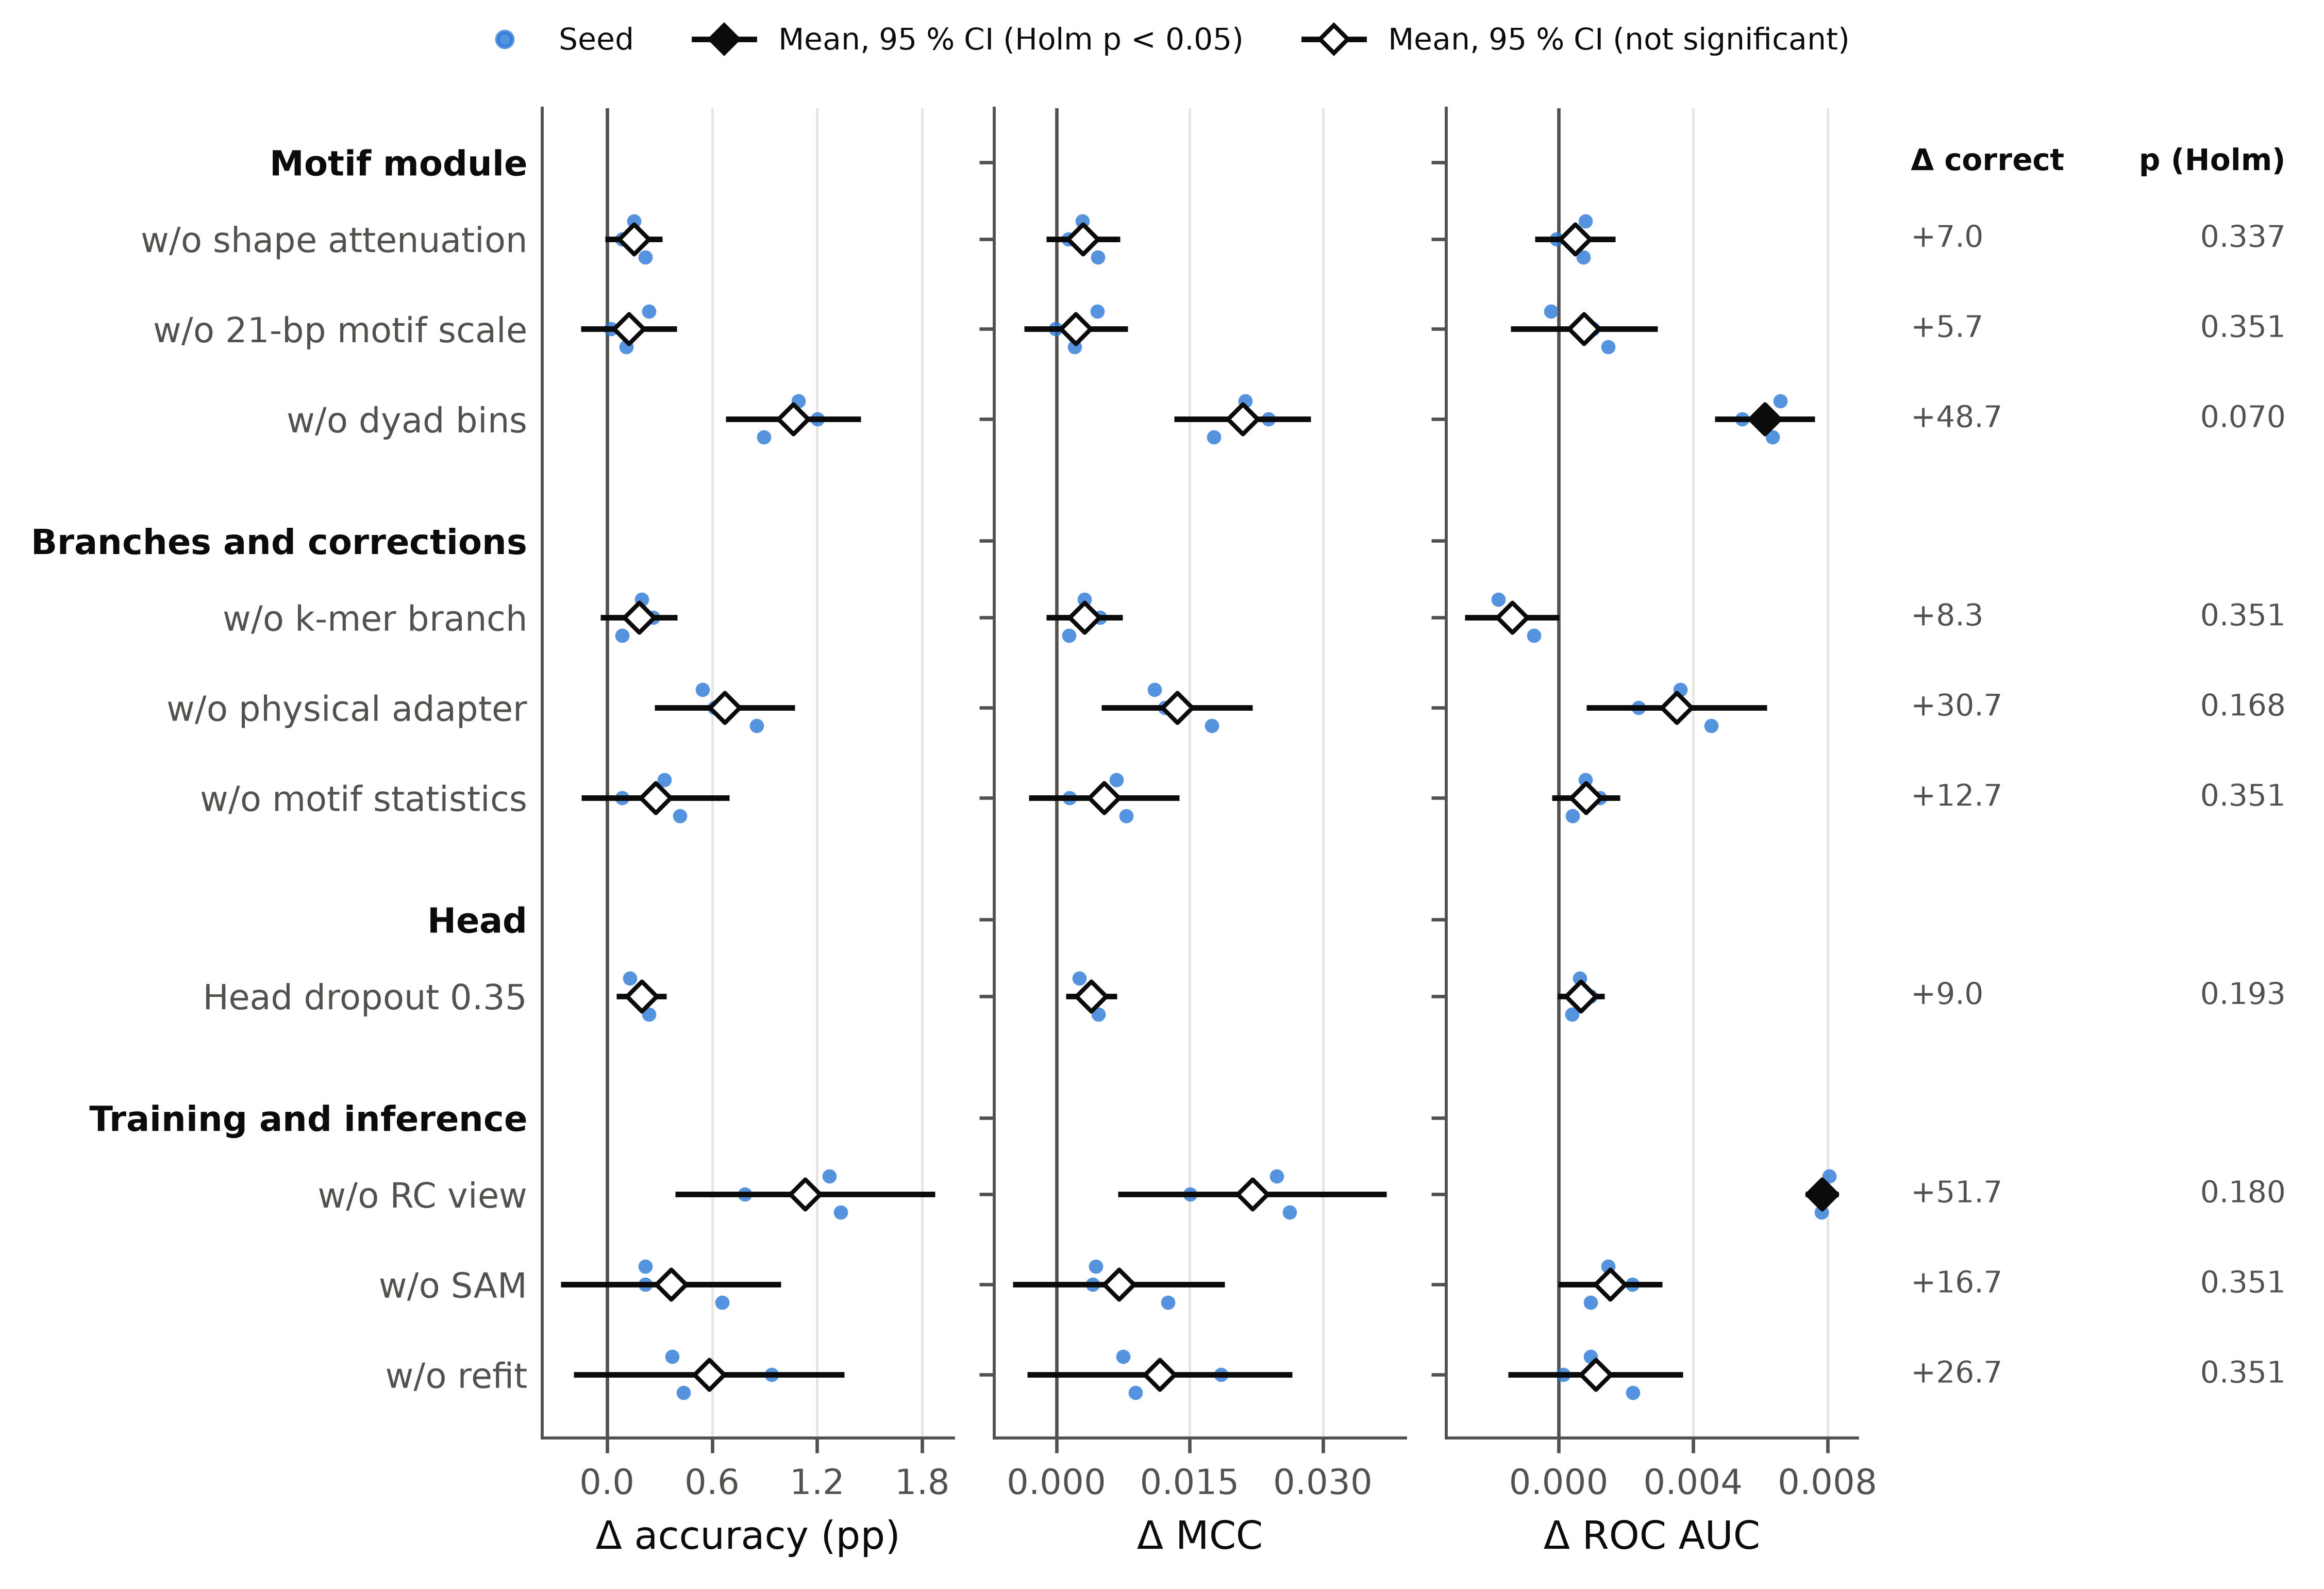

**boxplot_accuracy** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/architecture/figures/boxplot_accuracy.png`  
Architecture analysis: test accuracy of MorphoNup and of each variant on every outer test fold (3 seeds × folds; dots). Box: median and quartiles, whiskers 1.5 × IQR; diamond: mean; dashed line: MorphoNup mean. Fold-to-fold spread is larger than most differences, and folds of one seed share training rows, so the paired forest plot (deltas) carries the inference.

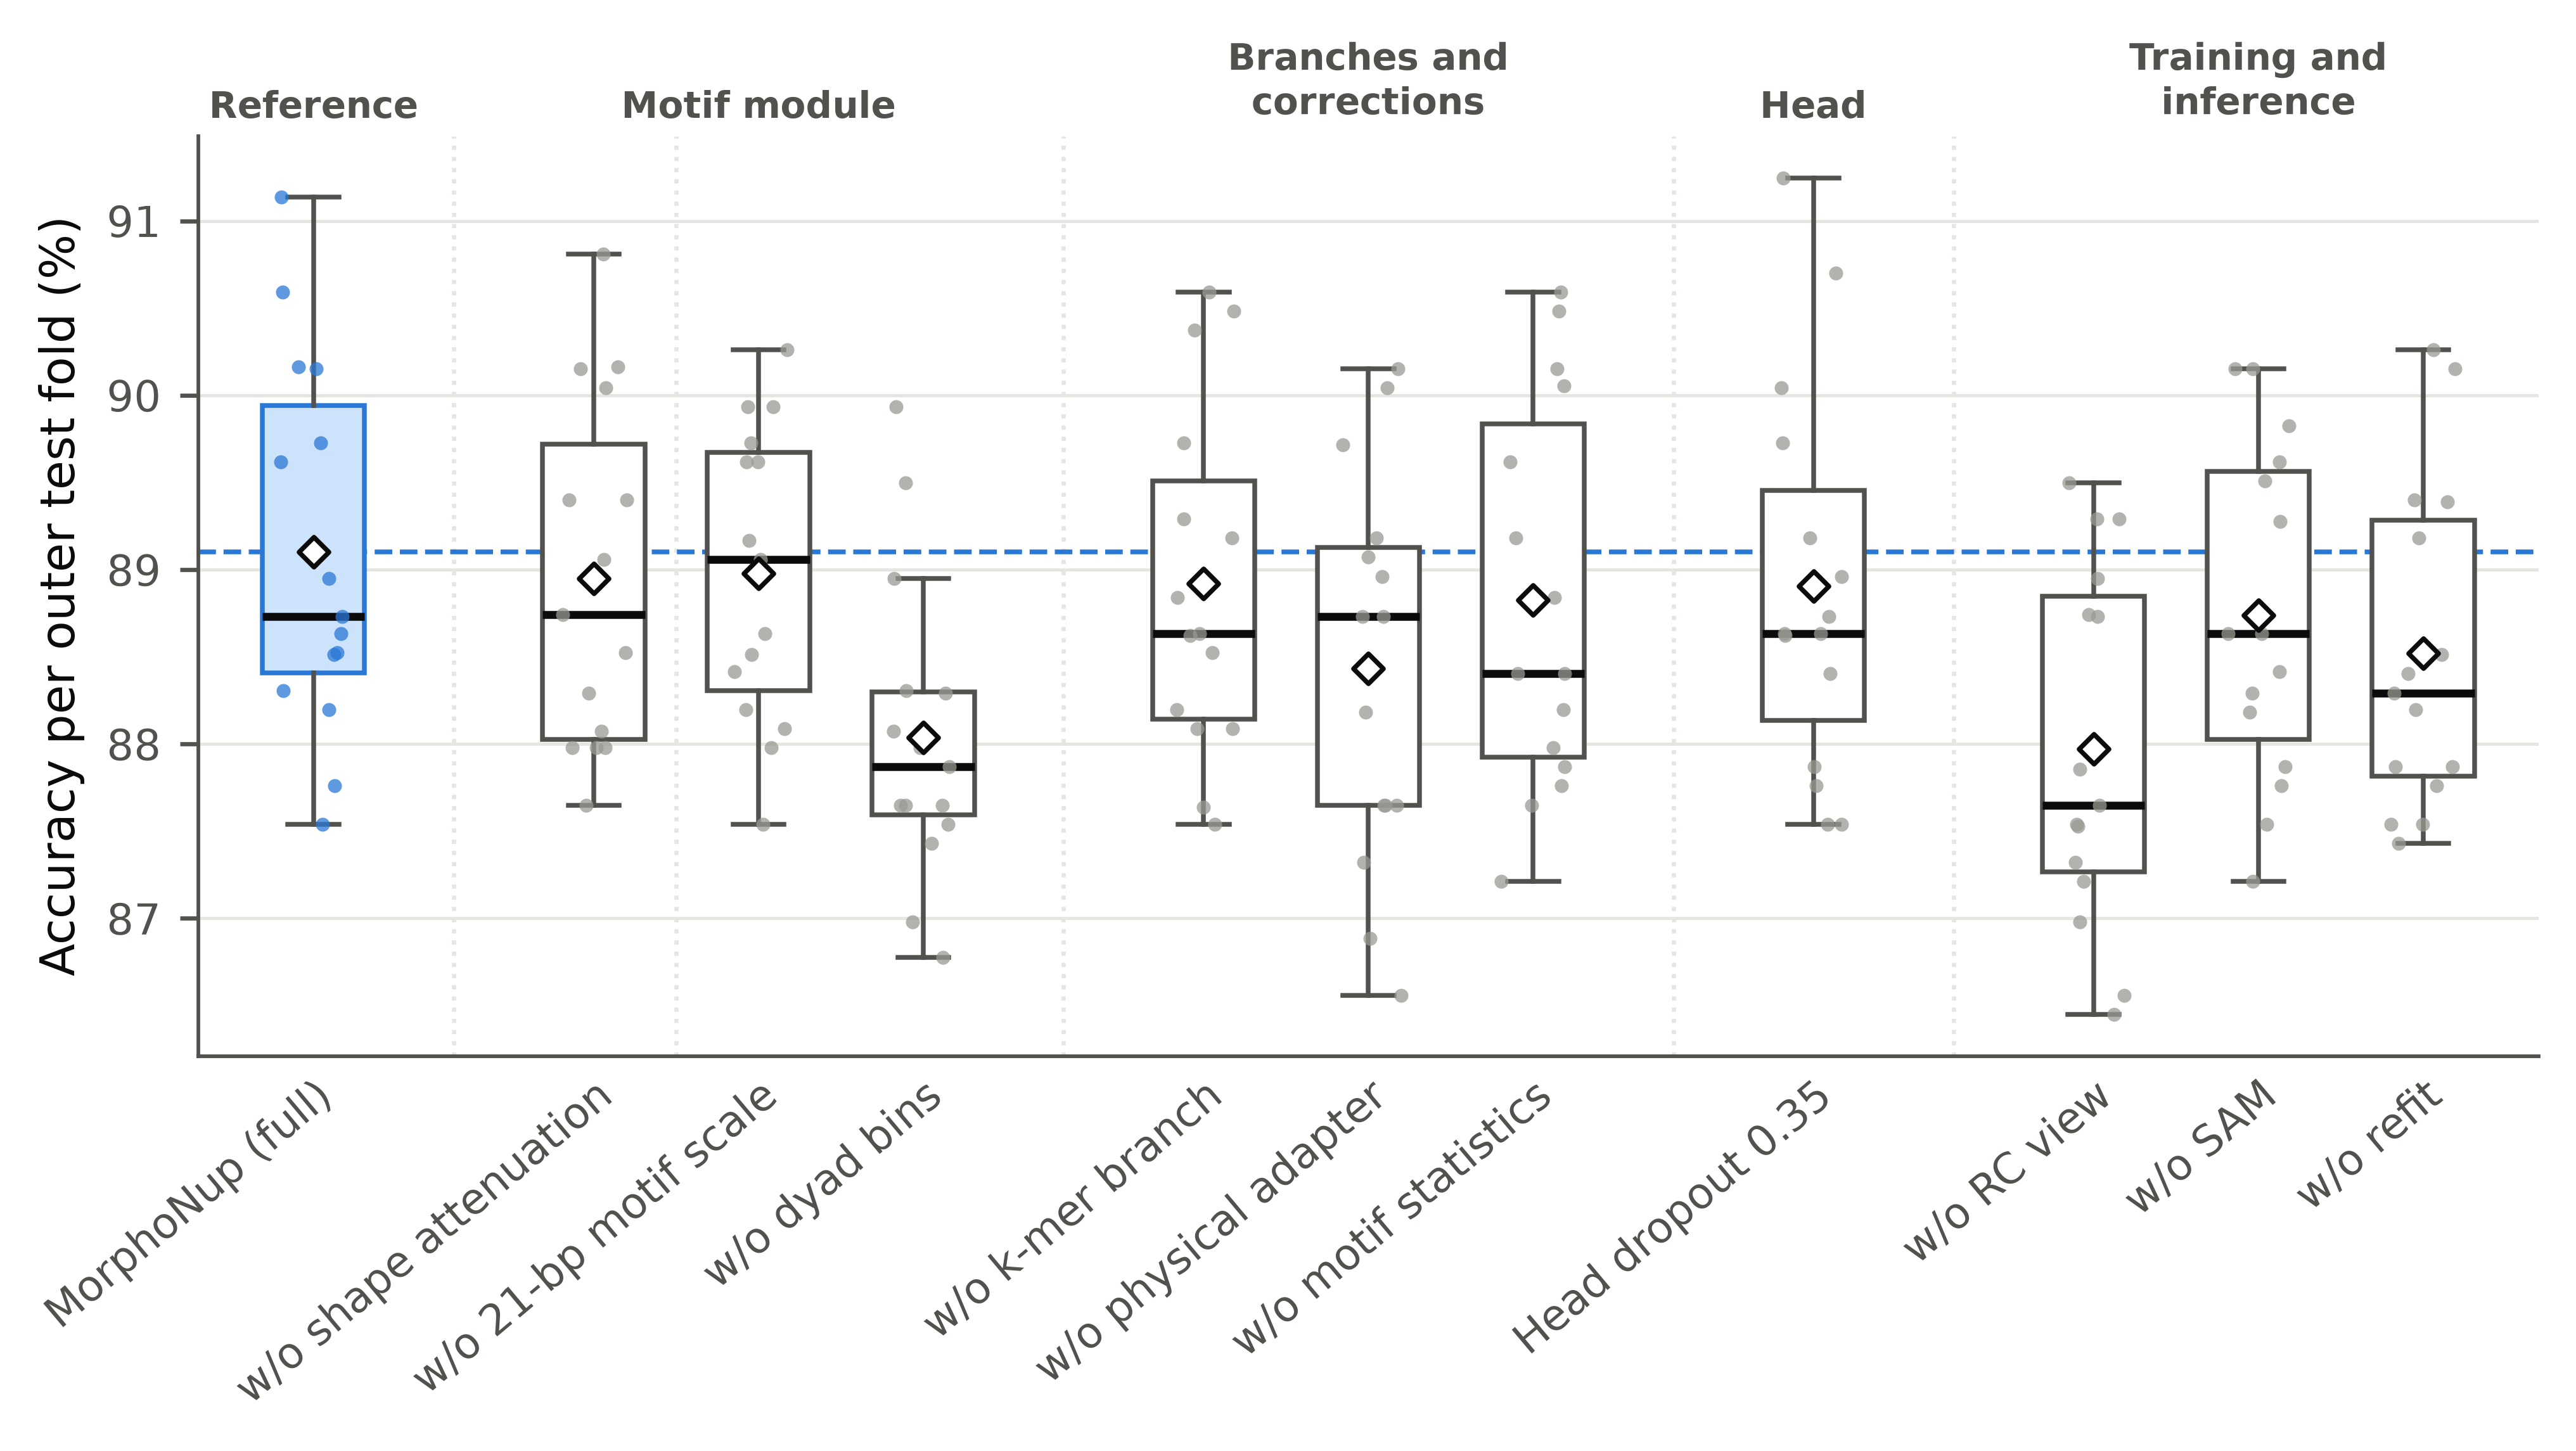

**delta_heatmap** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/architecture/figures/delta_heatmap.png`  
Architecture analysis: mean difference MorphoNup − variant for nine metrics (3 seeds; × 100). Blue: the variant is worse (the removed or changed component helps); red: the variant is better; bold: the 95 % t interval over seeds excludes 0.

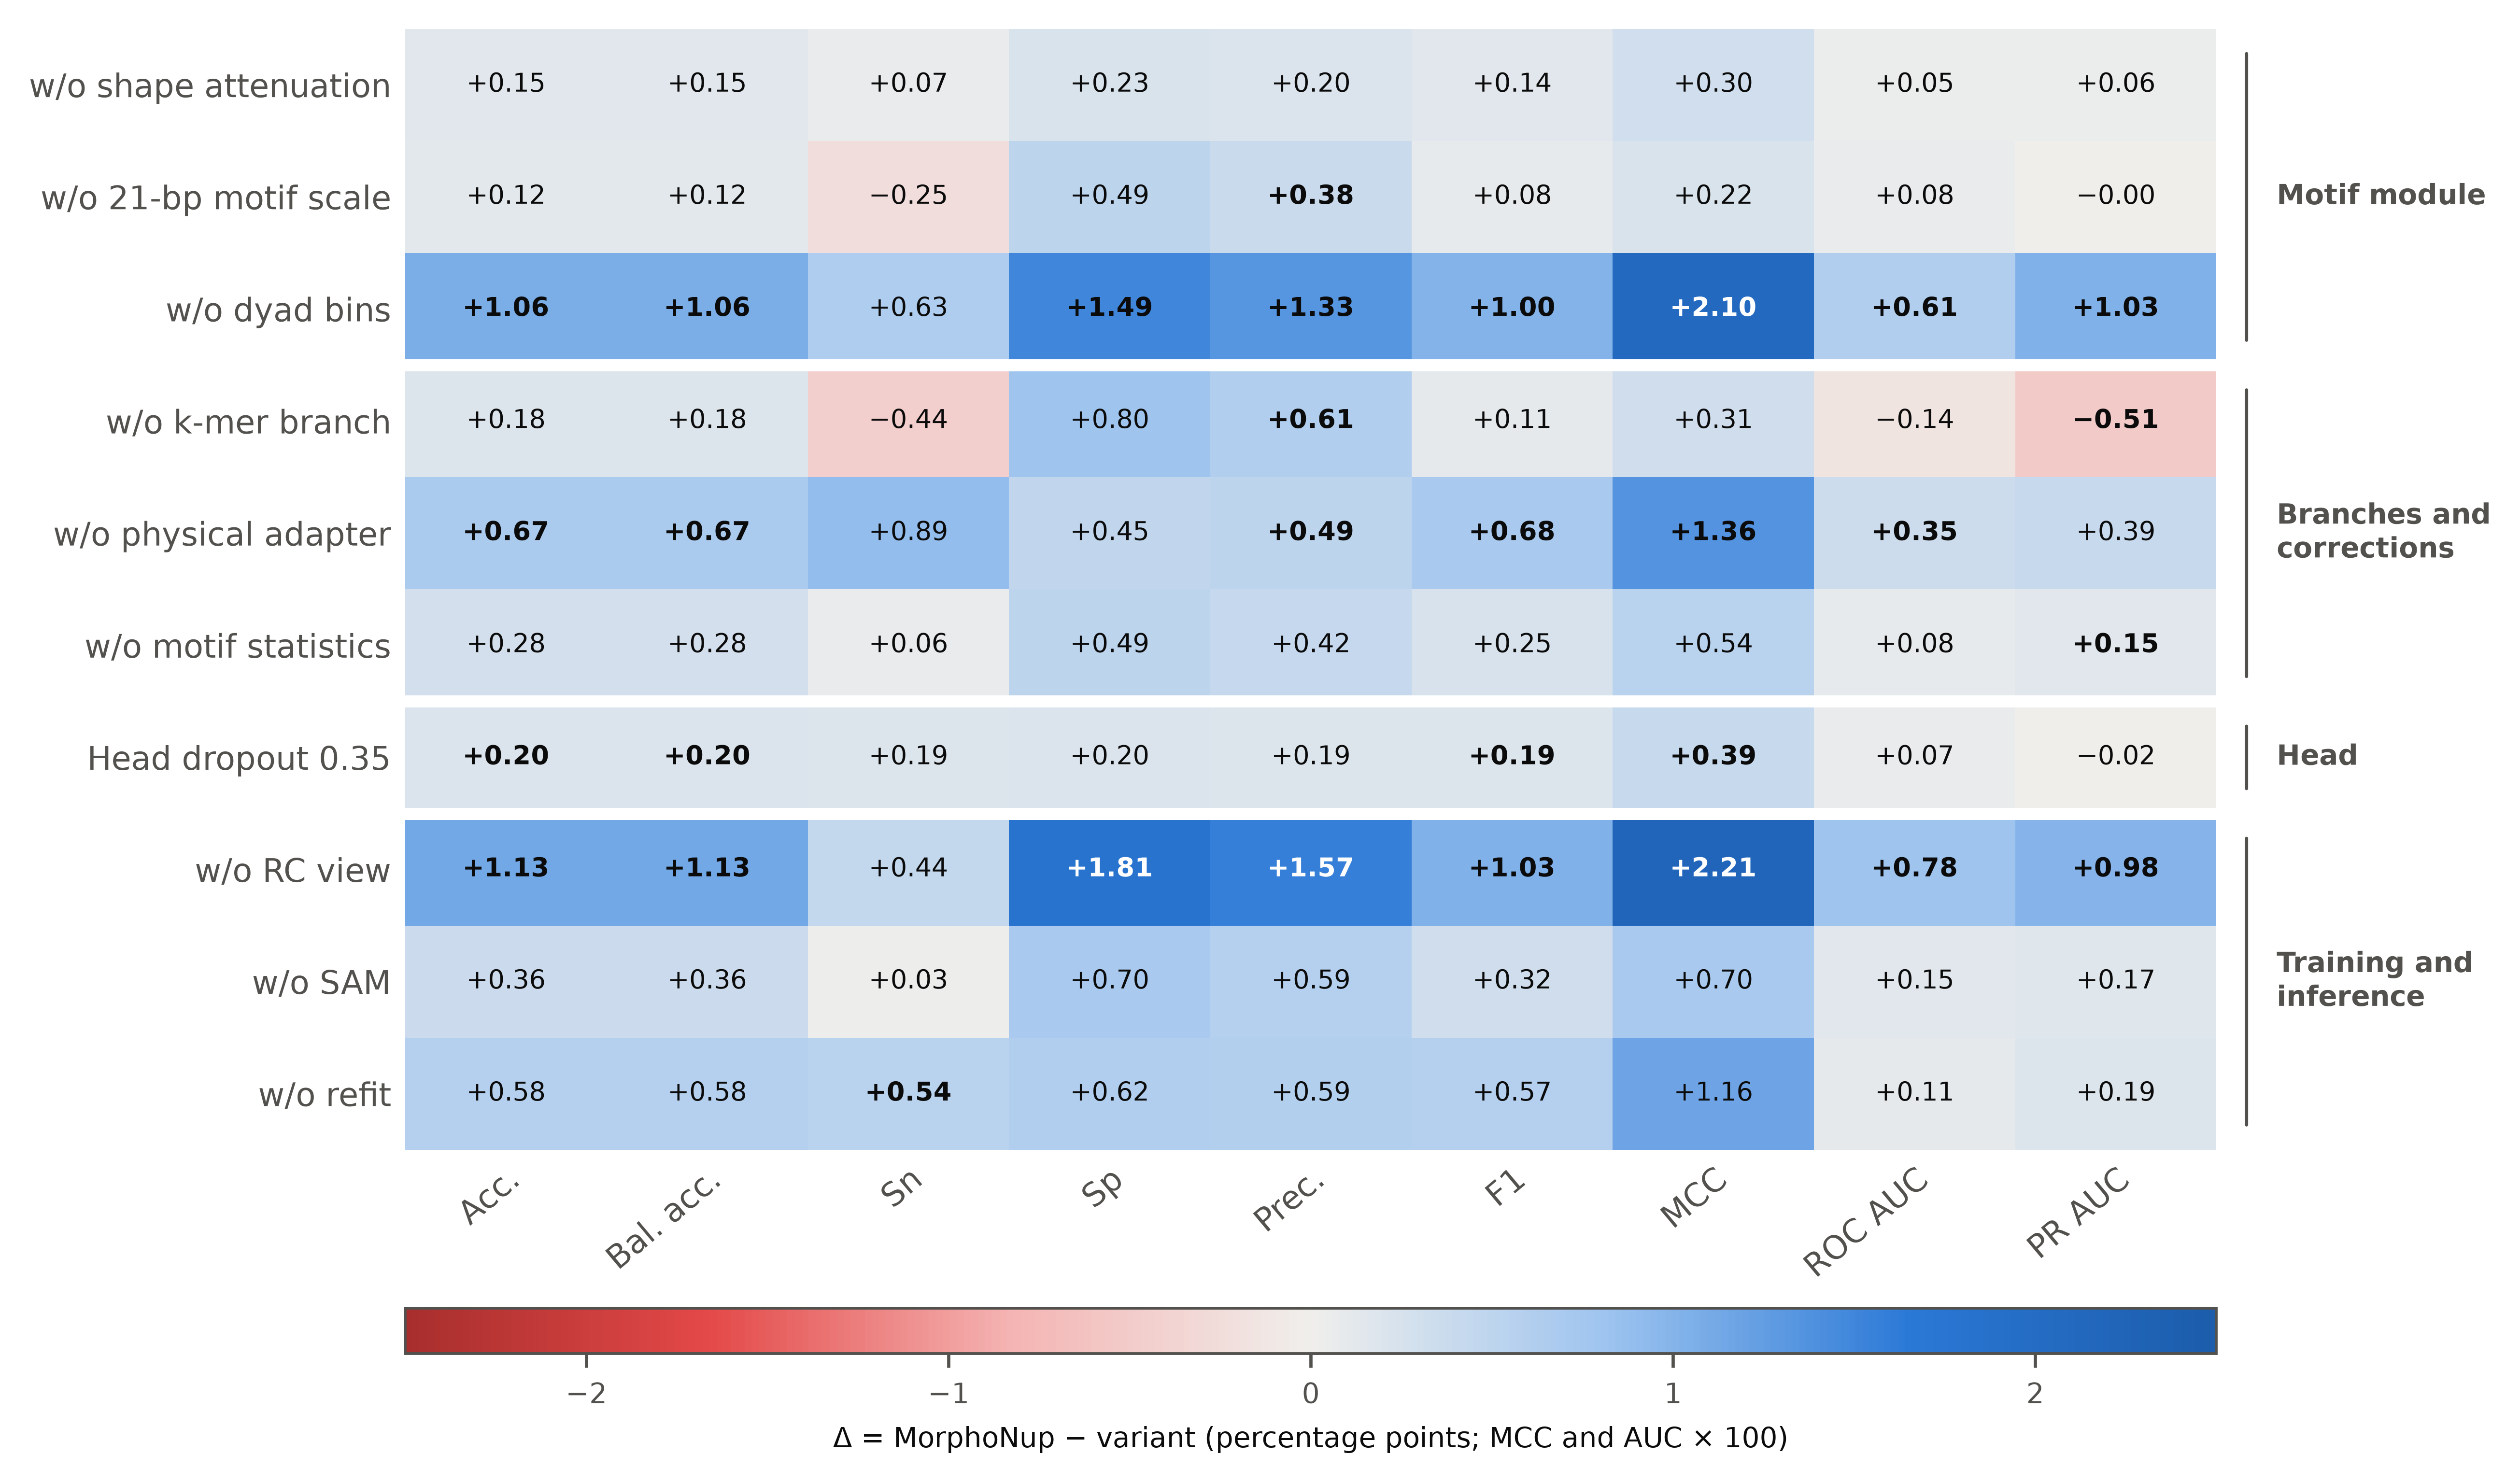

**metrics_panel** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/architecture/figures/metrics_panel.png`  
Architecture analysis: six pooled out-of-fold metrics of every variant (3 seeds; dots: seeds; tick: mean; bar: ± SD); dashed line and band: MorphoNup mean ± SD. Sensitivity = nucleosome recall, specificity = linker recall (threshold 0.5).

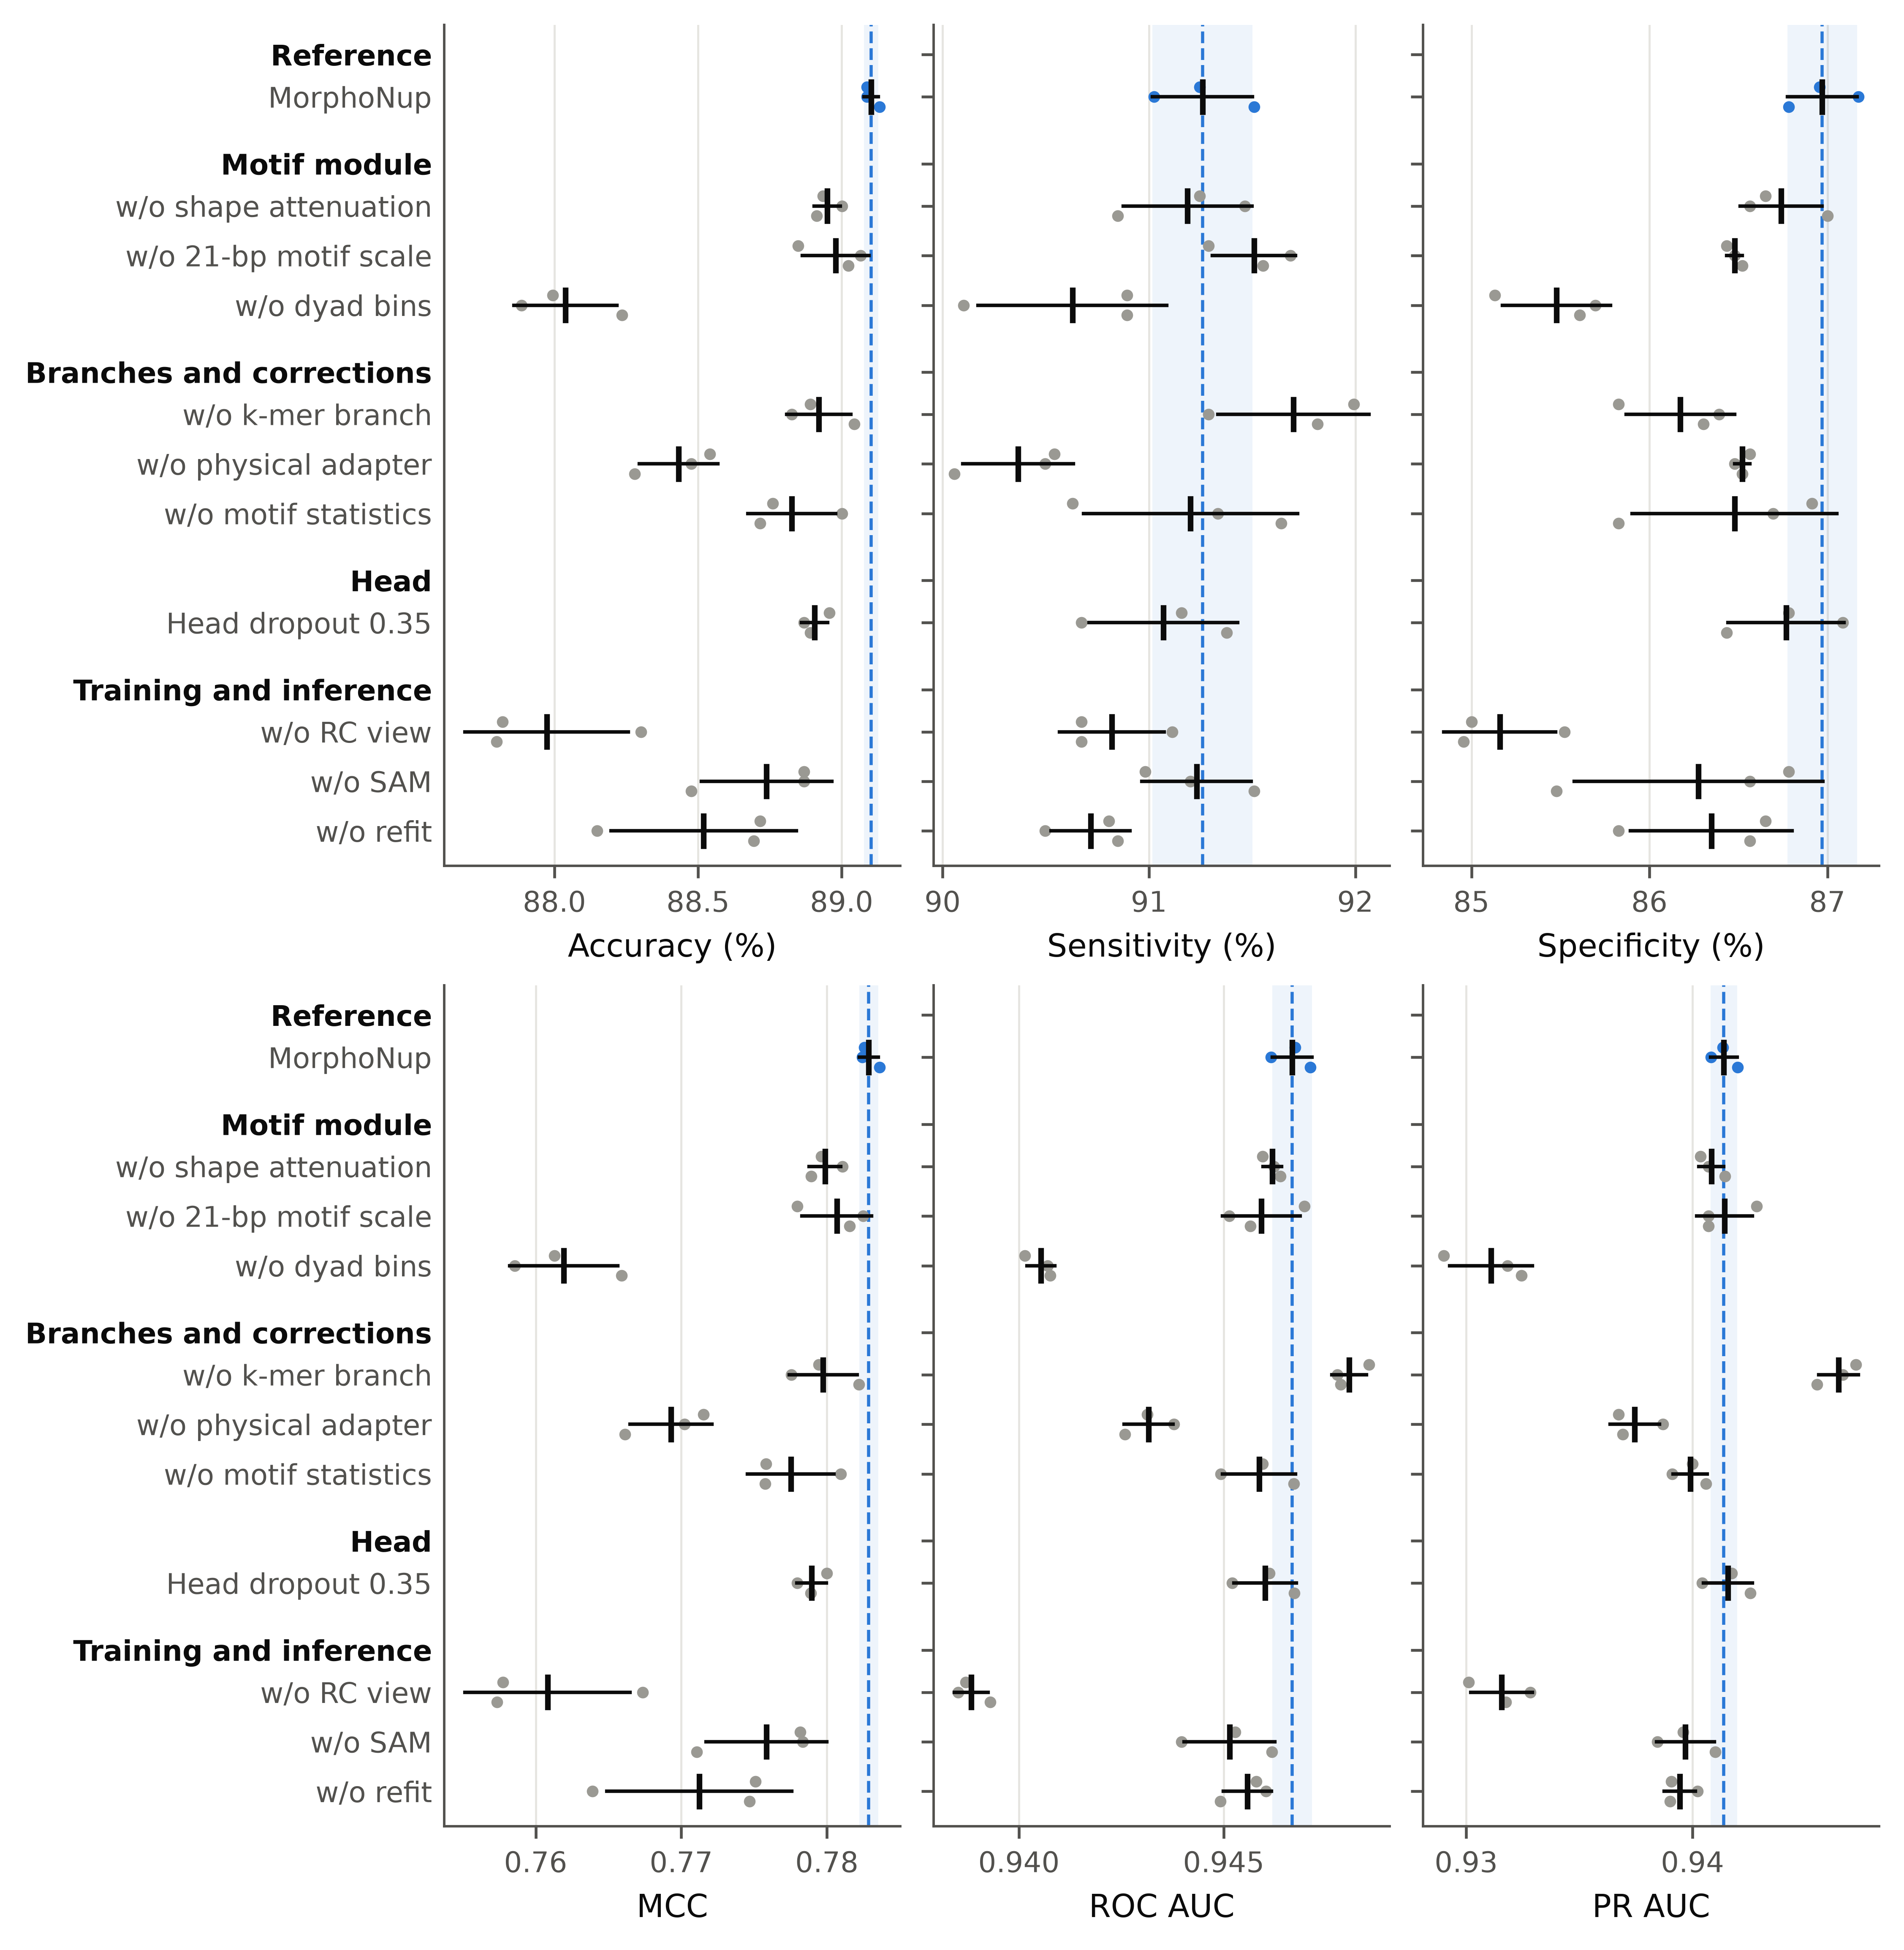

**accuracy** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/architecture/figures/accuracy.png`  
Architecture analysis: pooled out-of-fold accuracy of each variant (dots: seeds; tick: mean; bar: ± SD); dashed line and band: MorphoNup mean ± SD.

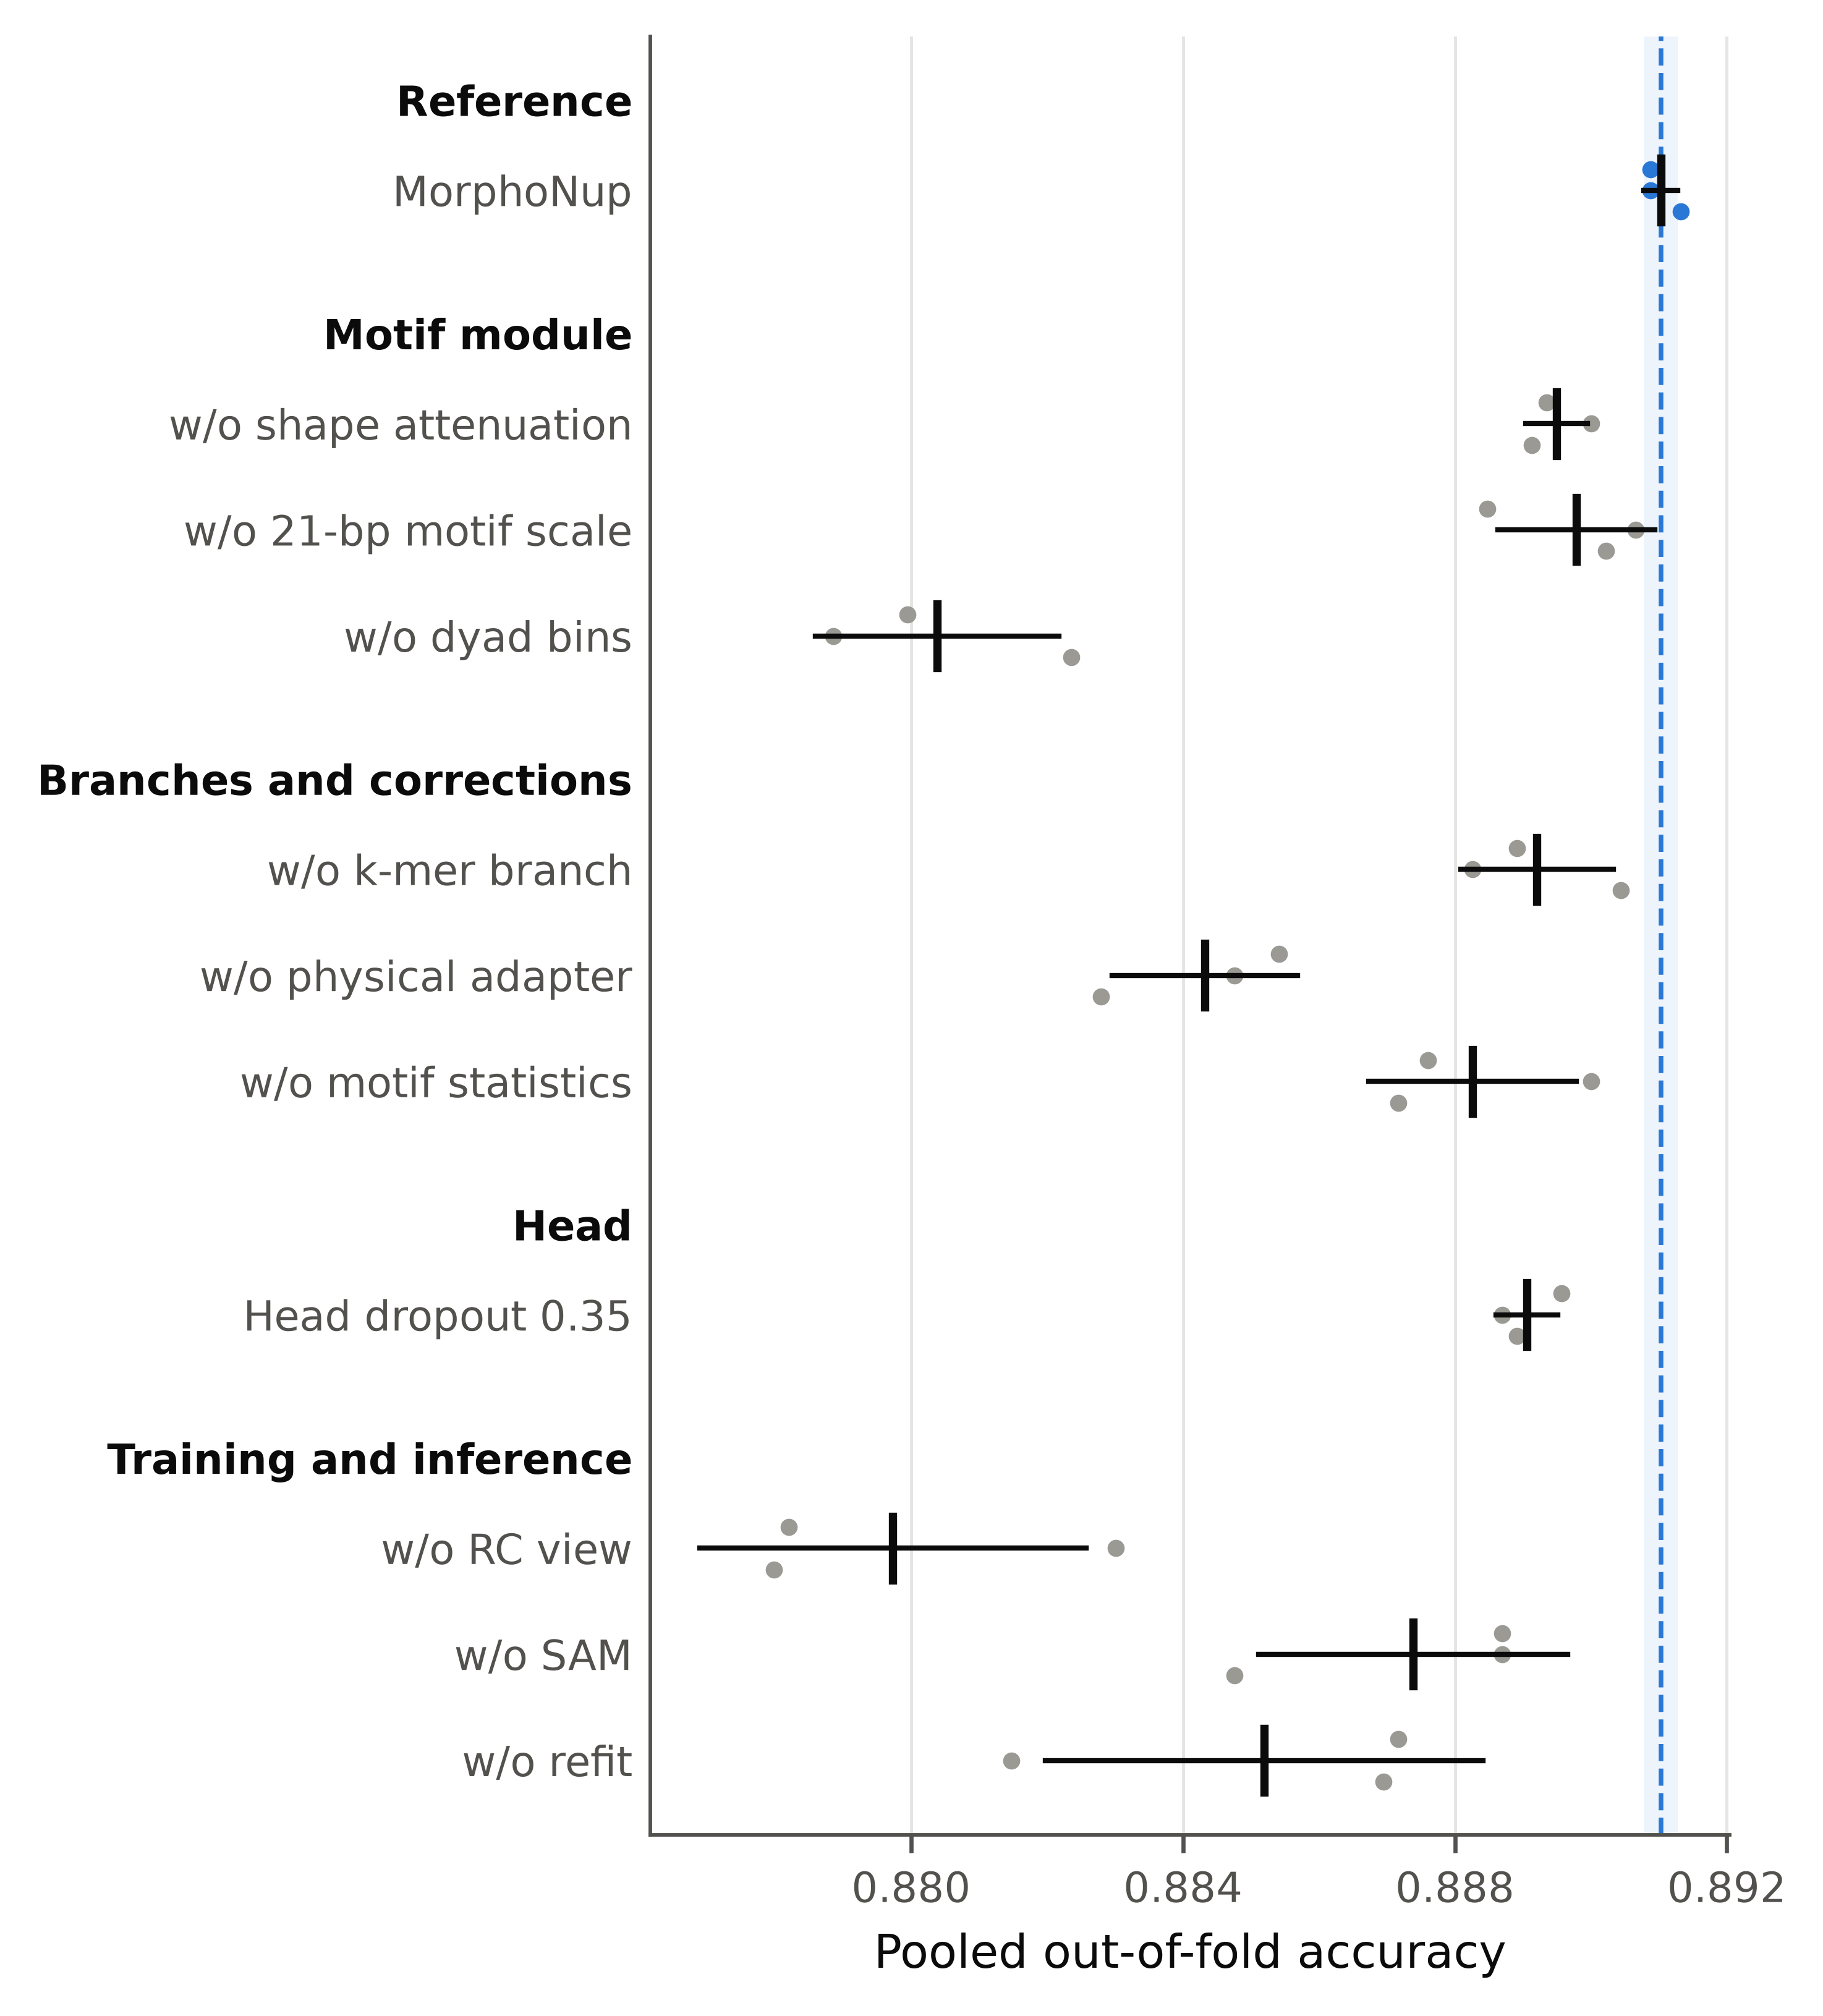

**discordance** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/architecture/figures/discordance.png`  
Architecture analysis: the discordant test sequences behind the McNemar test, mean per seed (3 seeds). Blue: classified correctly by MorphoNup only; red: by the variant only; net = blue − red = difference in correct sequences.

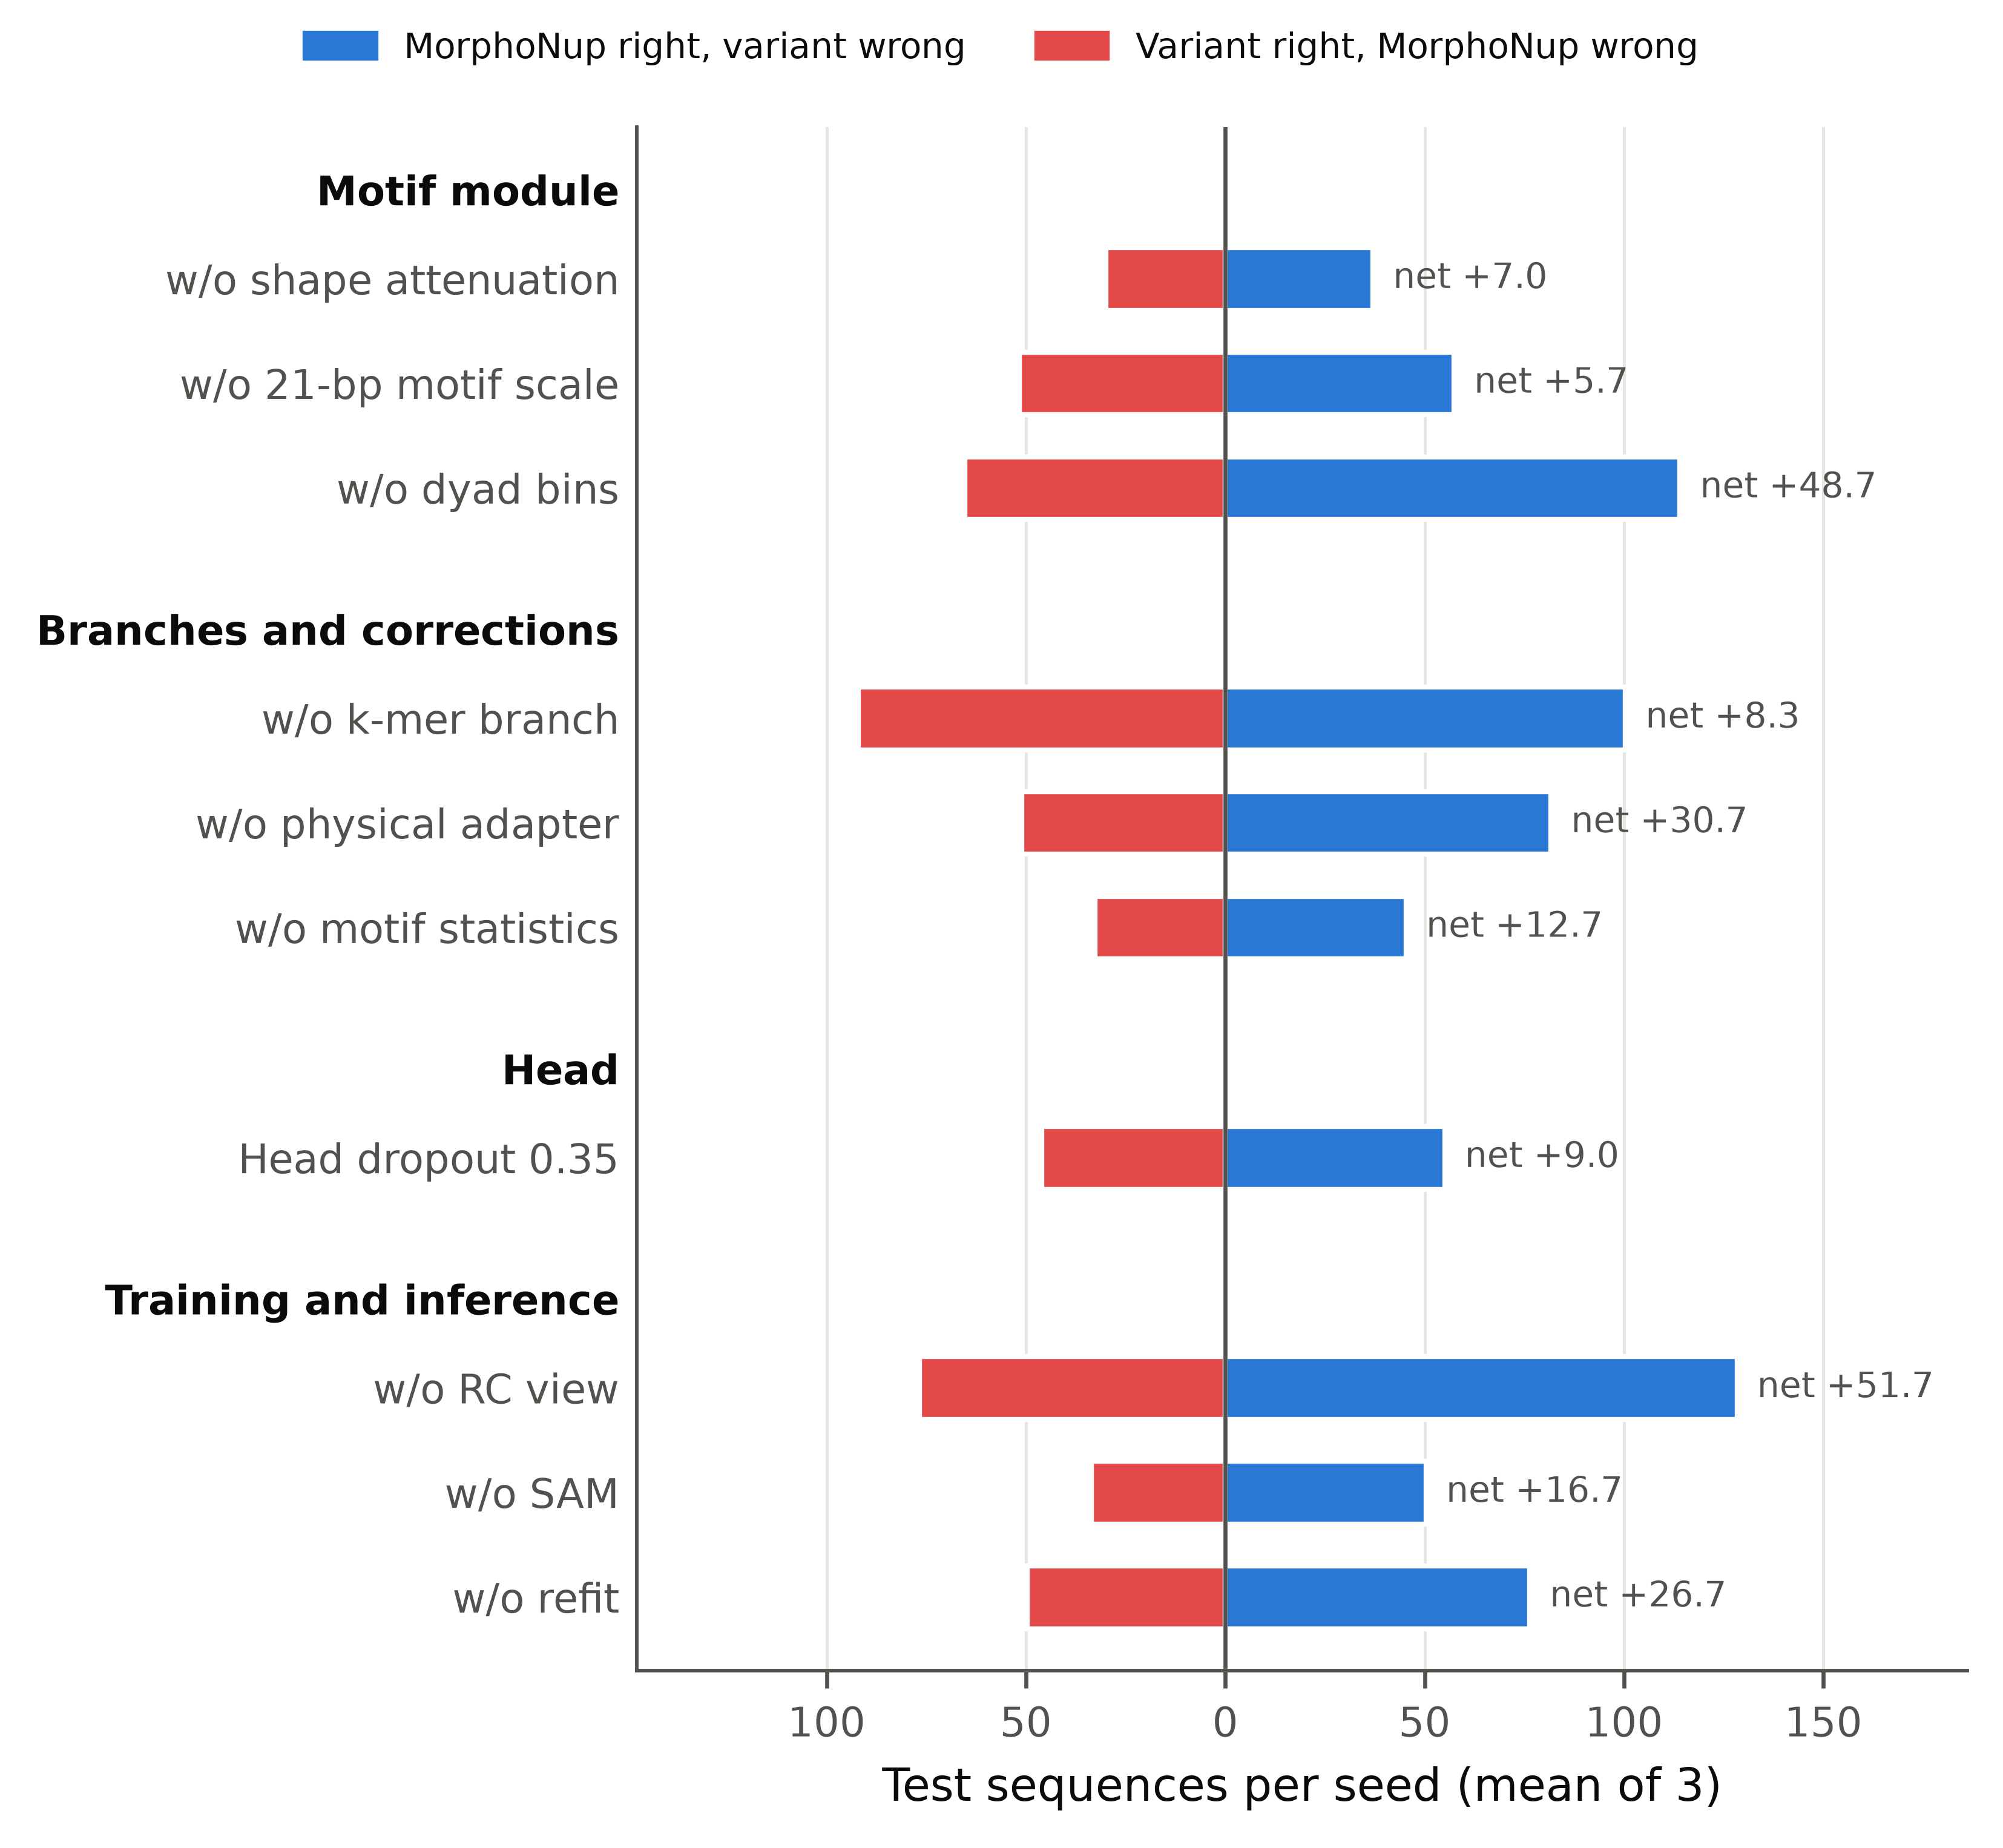

**fold_deltas** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/architecture/figures/fold_deltas.png`  
Architecture analysis: MorphoNup minus variant accuracy on each outer test fold of each seed (dots; box: median and quartiles, whiskers 1.5 × IQR). Folds of one seed share training rows and fold-to-fold noise is large, so this panel is descriptive; inference uses the seed-level test.

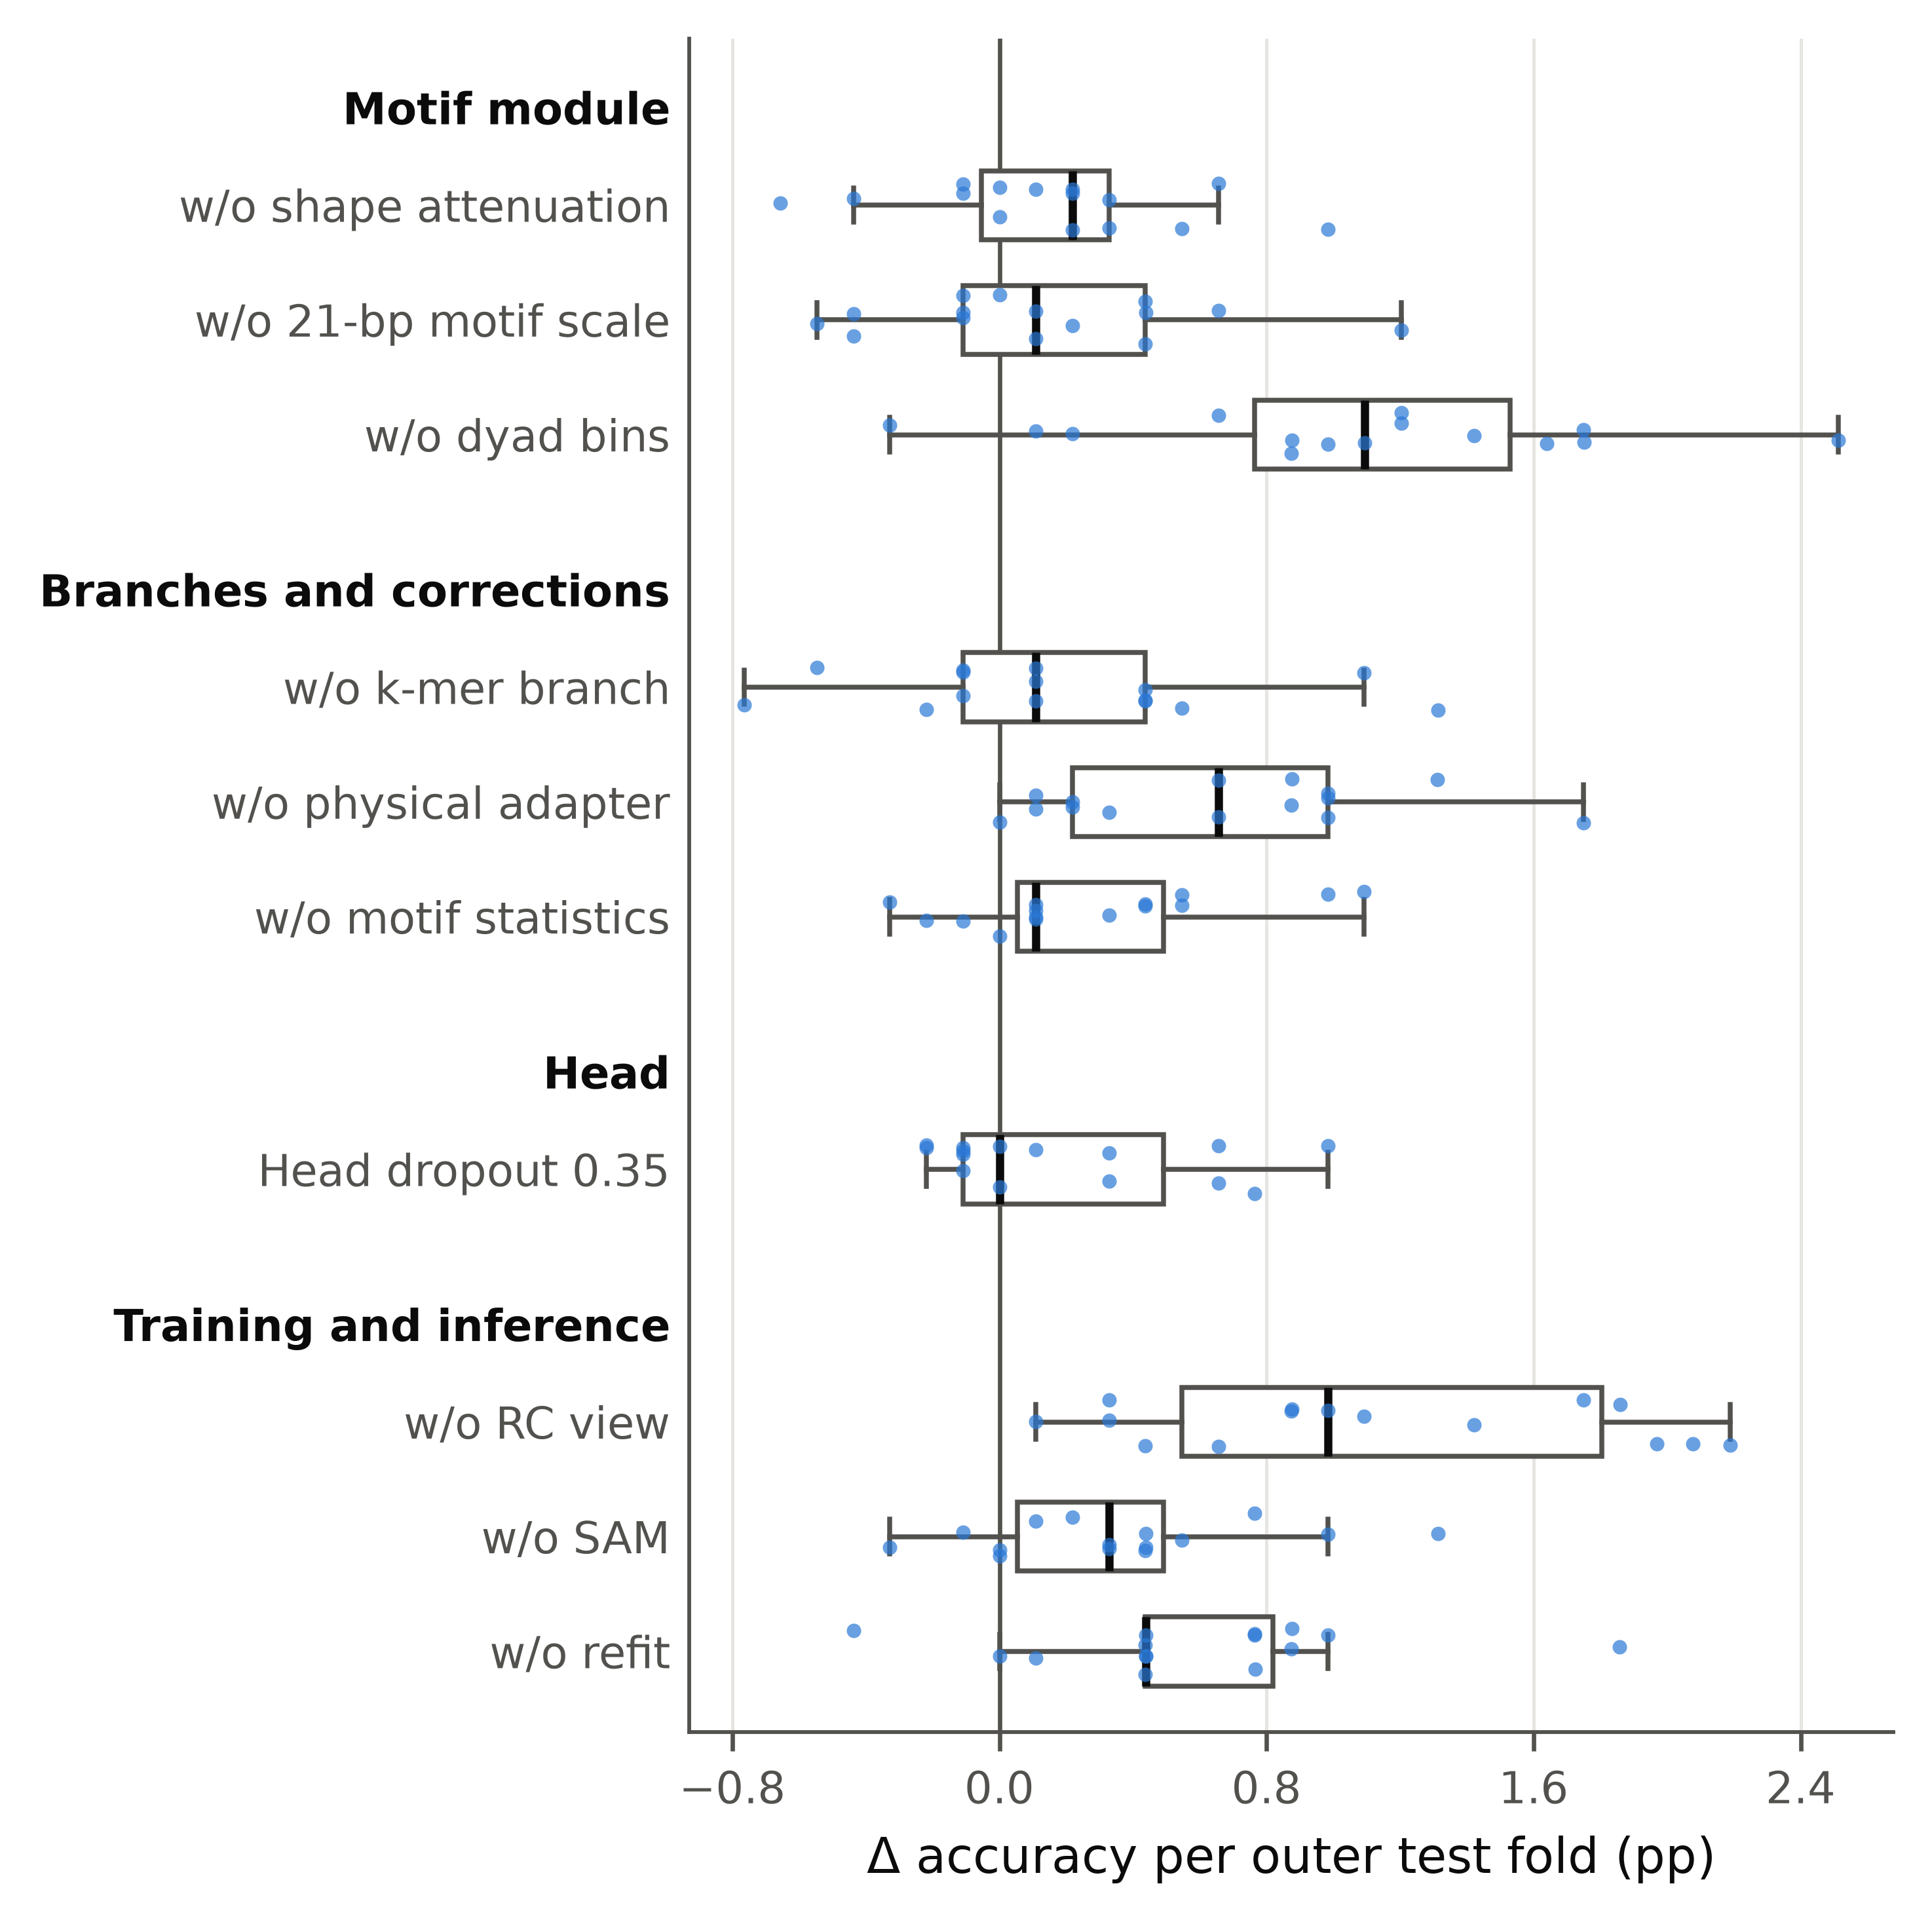

**roc_pr_parts** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/architecture/figures/roc_pr_parts.png`  
Architecture analysis: pooled out-of-fold ROC (top) and precision–recall (bottom) curves of MorphoNup and the variants of each part, seed 151000, axes zoomed to the upper-left (ROC) and upper-right (PR) region where the curves separate; legend: ROC AUC / average precision, mean over seeds. Differences of a few thousandths of AUC are hard to see as curves; the forest plot and tables give them.

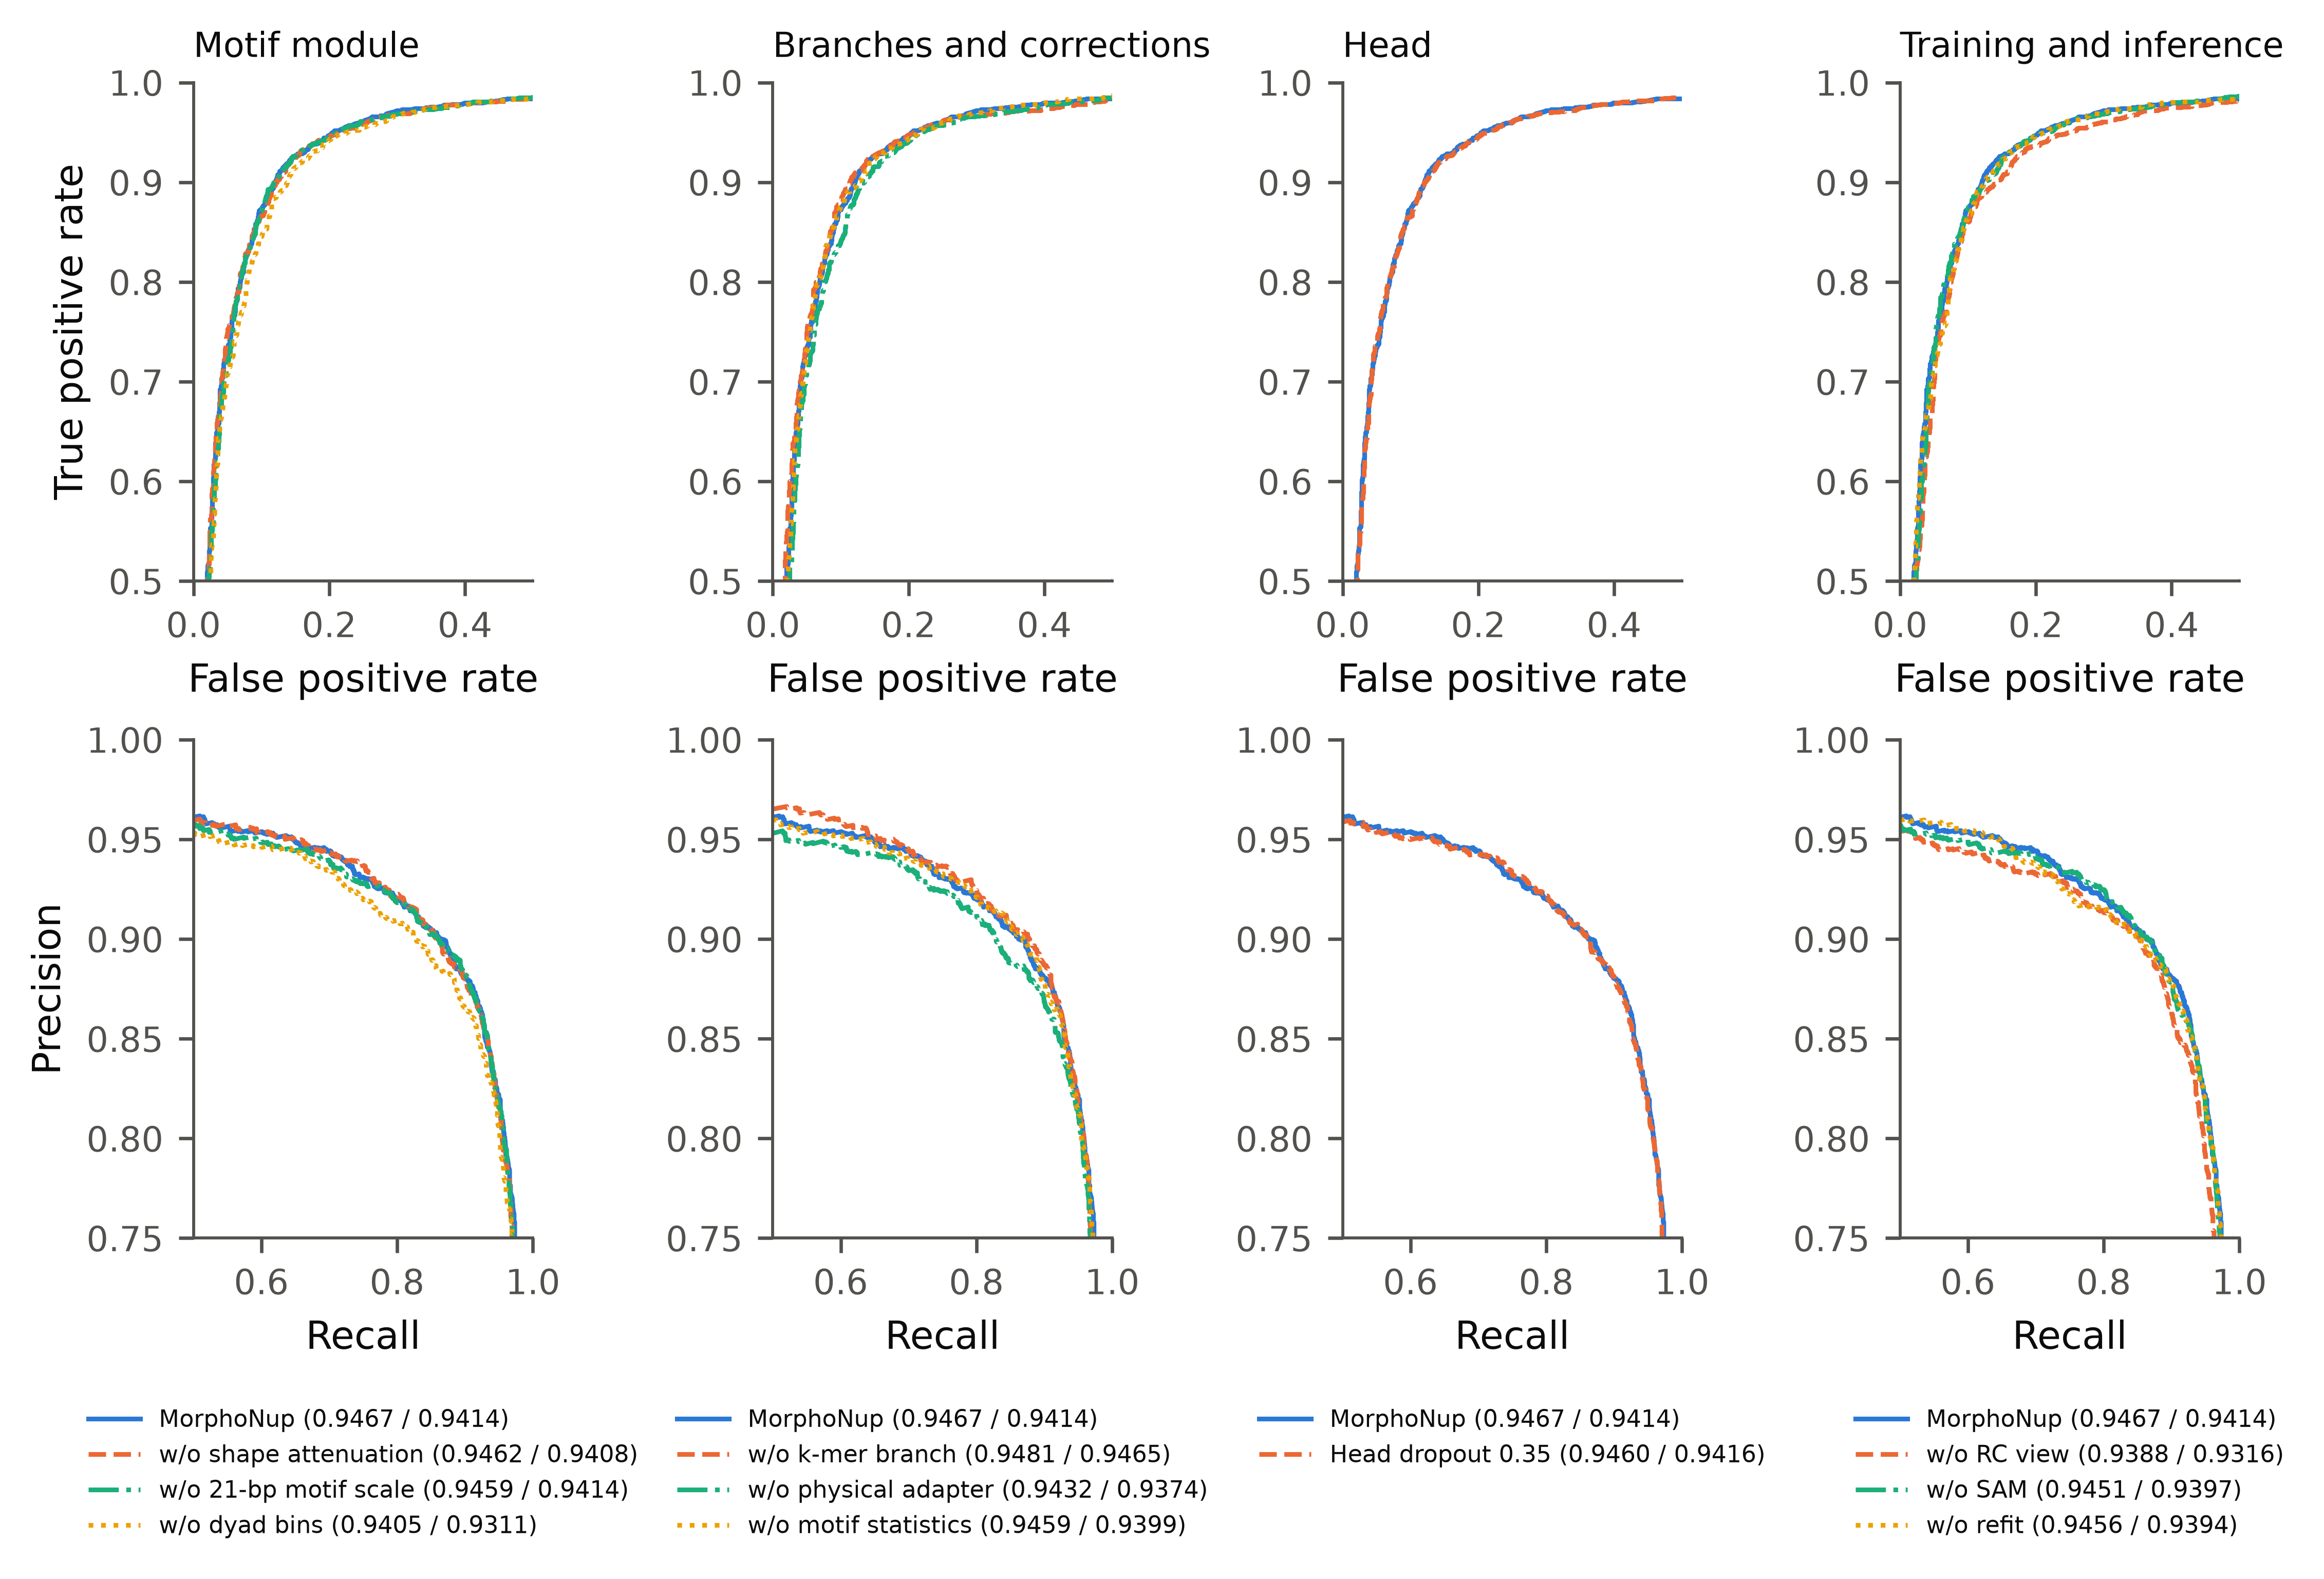

**training_curves** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/architecture/figures/training_curves.png`  
Architecture analysis: log loss on the tune rows per epoch of the base runs, mean over every outer fold and seed, for MorphoNup and the variants of each part, from epoch 8 (where checkpoint selection starts); a curve stops when fewer than half of its folds are still training (early stopping), so its last epochs average only the longer-running folds.

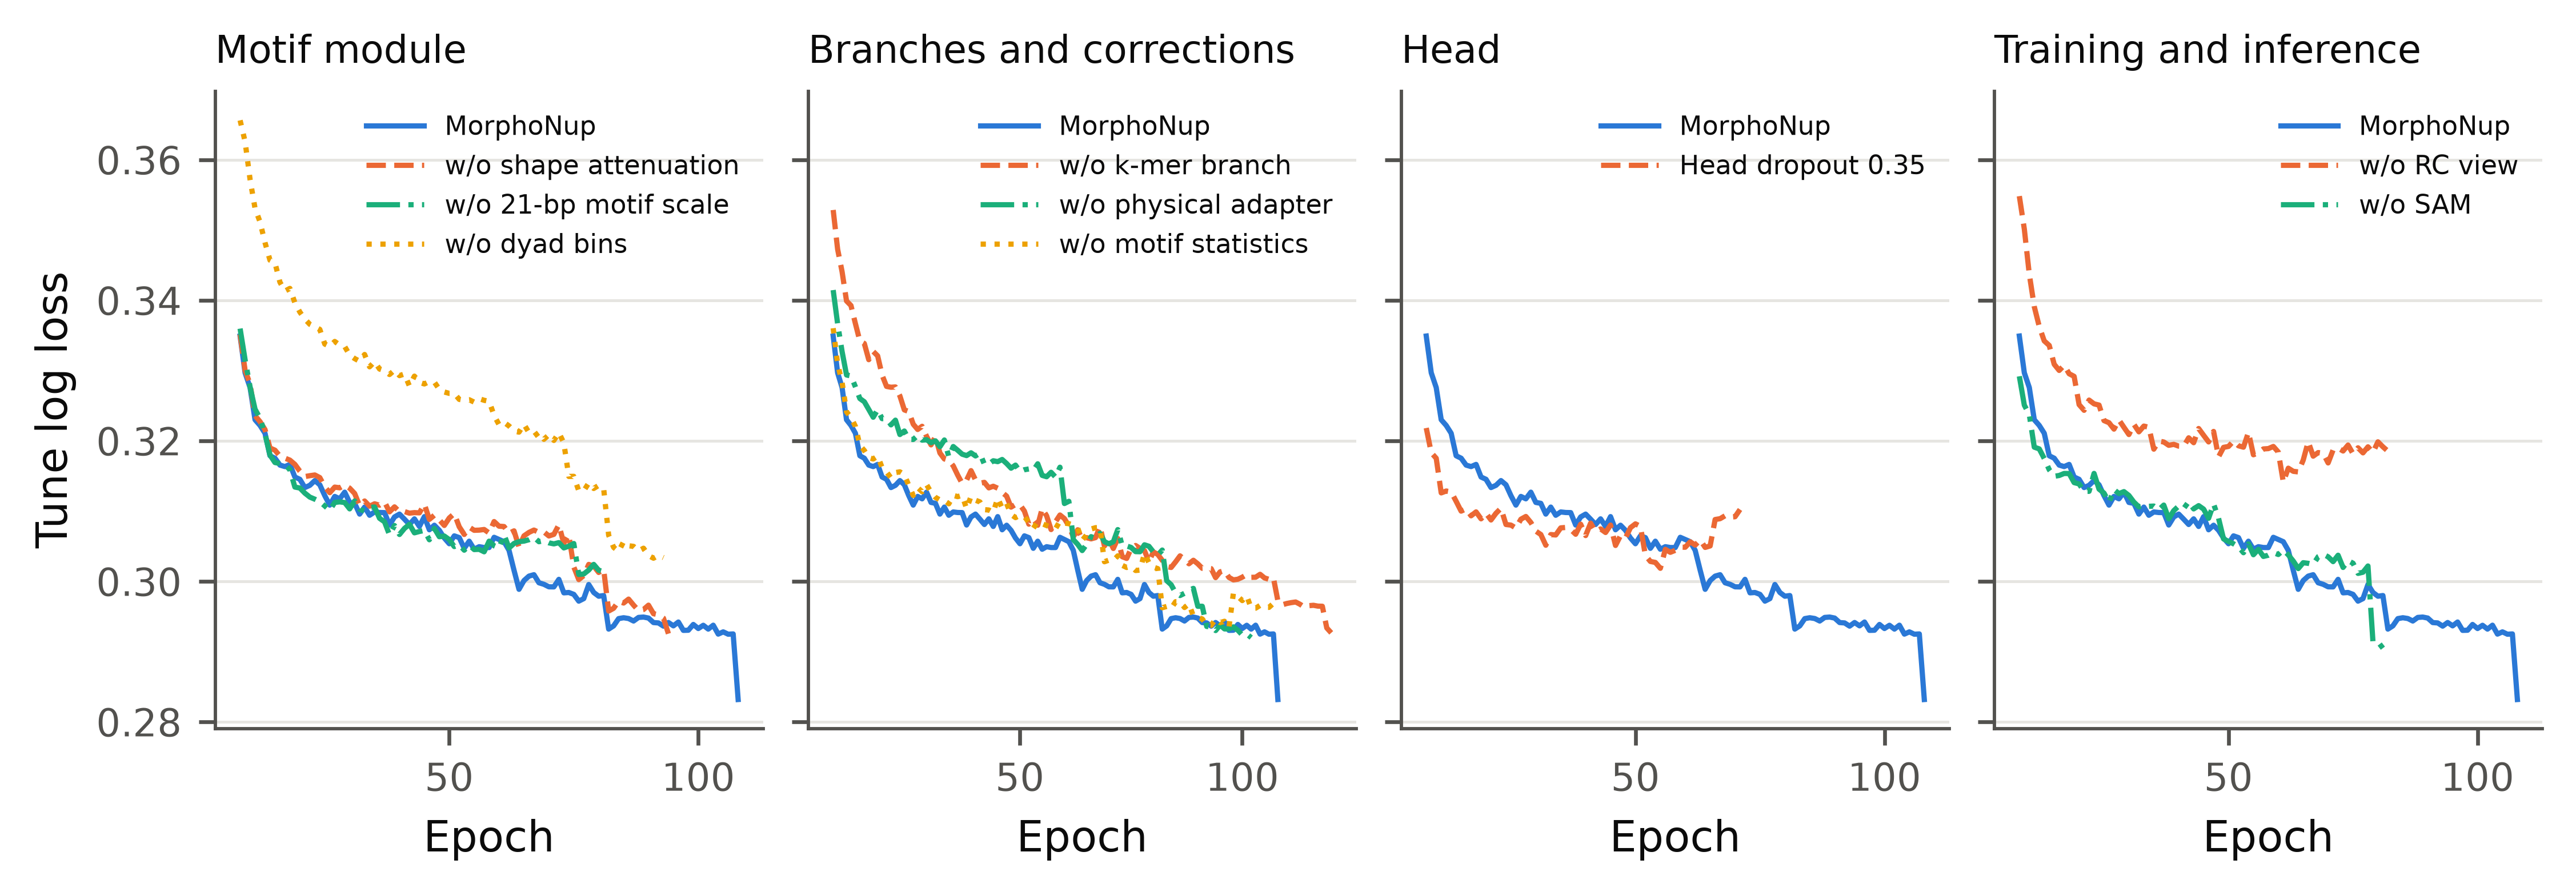

**training_diagnostics** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/architecture/figures/training_diagnostics.png`  
Architecture analysis: per outer fold and seed, the epoch chosen on the tune rows (left; cap 120) and the gap between training and test accuracy (right) of the reported model. Box: median and quartiles, whiskers 1.5 × IQR; MorphoNup in blue.

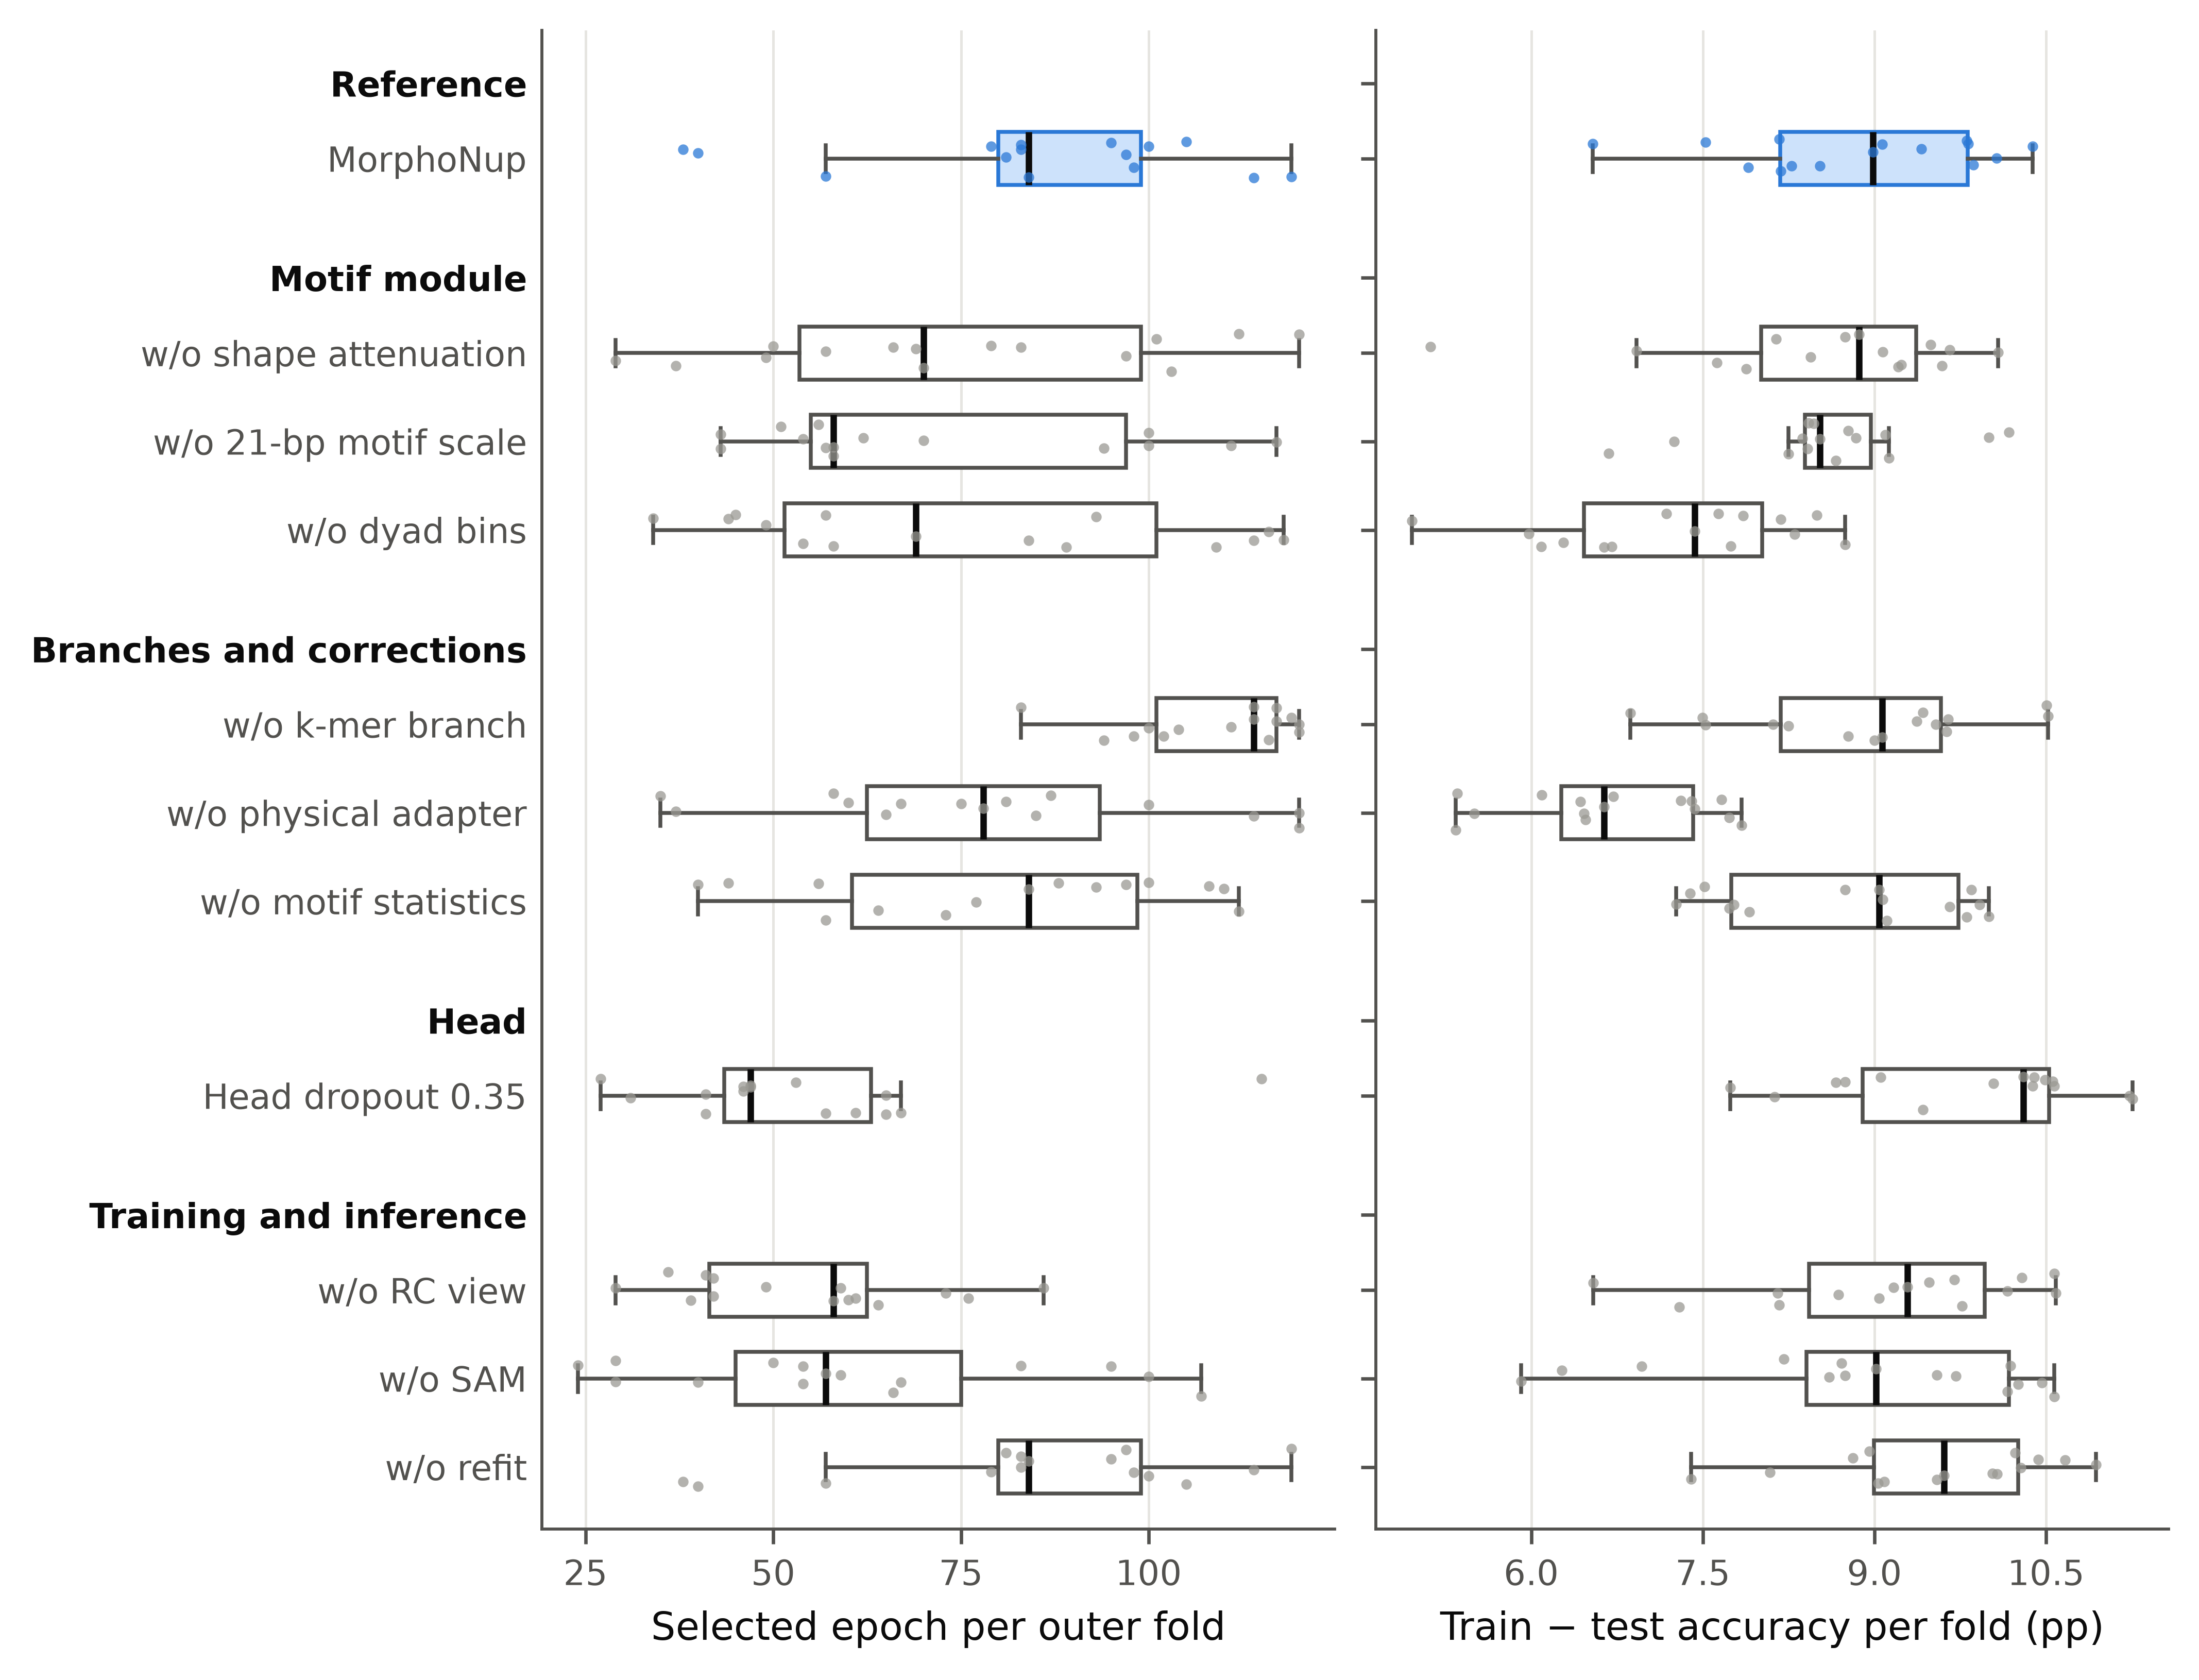

**parameters** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/architecture/figures/parameters.png`  
Architecture analysis: parameter count of each variant (MorphoNup in blue).

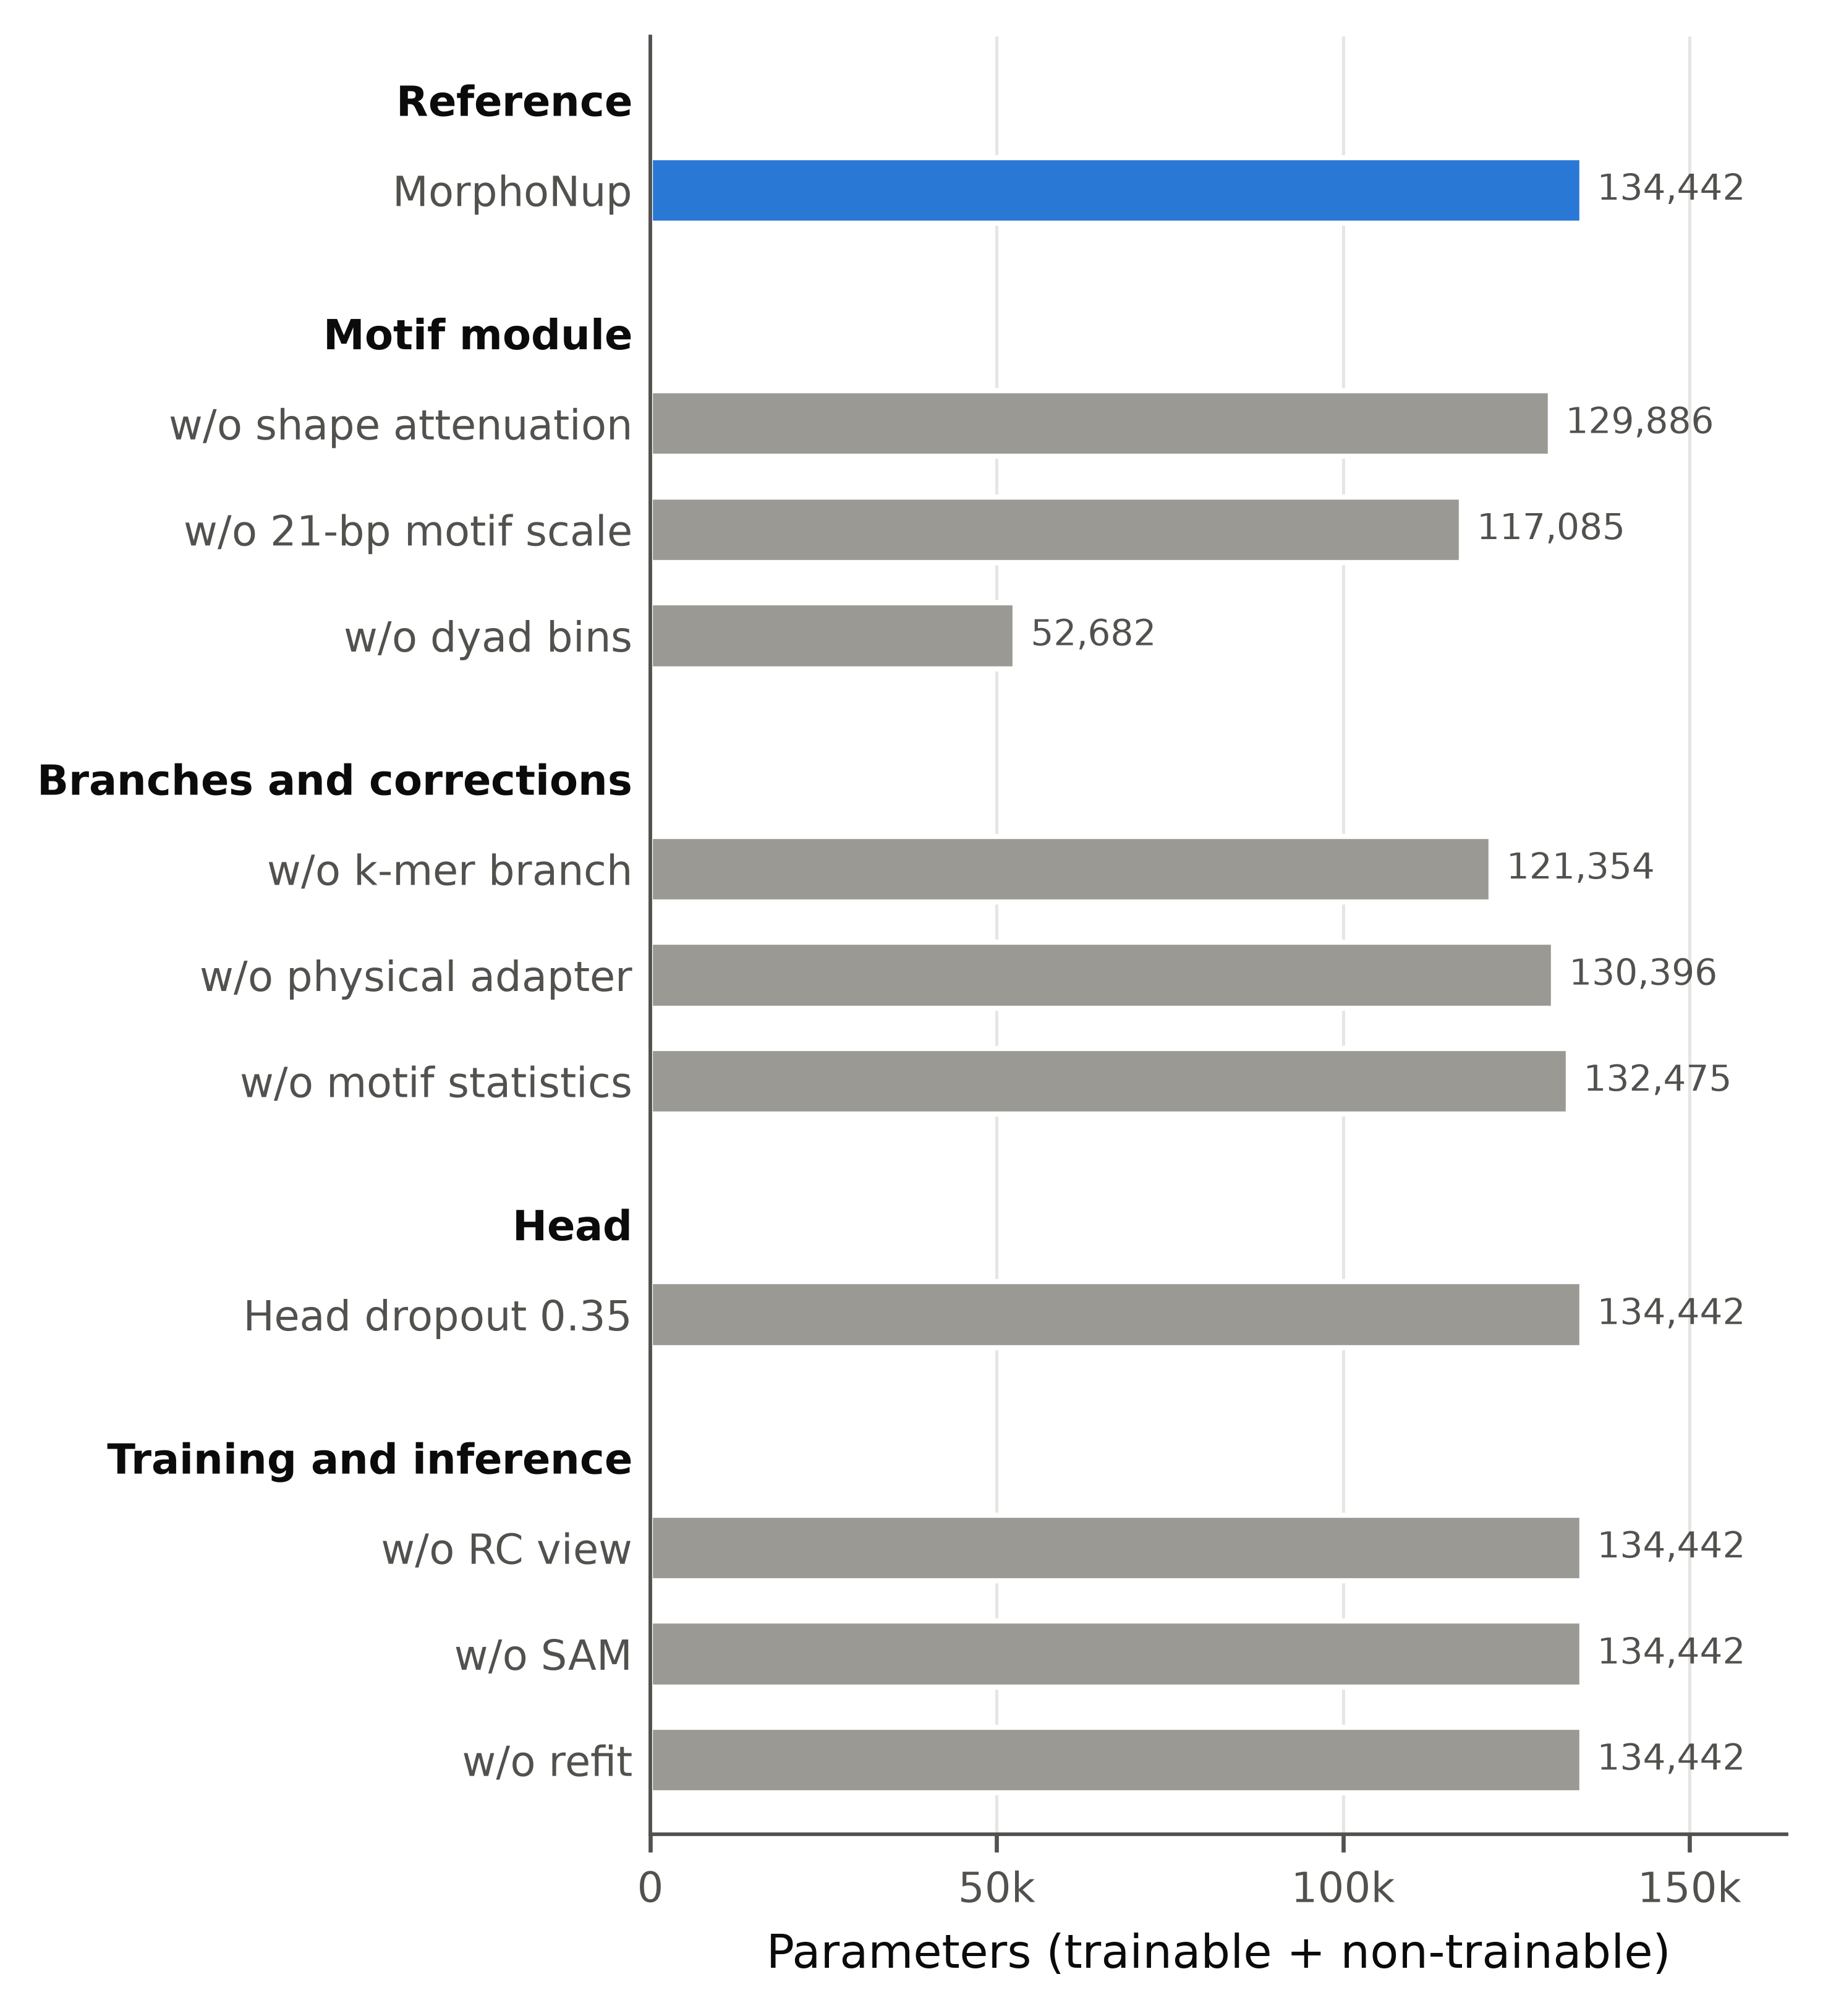

In [7]:
if (OUT / "figures").exists():
    for name in ('deltas', 'boxplot_accuracy', 'delta_heatmap', 'metrics_panel', 'accuracy', 'discordance', 'fold_deltas', 'roc_pr_parts', 'training_curves', 'training_diagnostics', 'parameters'):
        if (OUT / "figures" / f"{name}.png").exists():
            show(OUT / "figures" / f"{name}.png")
else:
    print("No figures yet: train at least one arm (RUN_MODE = 'background').")

Per-seed and per-fold numbers: `seed_metrics.csv`, `fold_deltas.csv`, `comparison.csv`, `manuscript_table.csv` in the same folder. Each arm's own run figures are under `results/<dataset>/k<K>/<arm>/`.